# New wd=0.1 benchmark follow-up (execution preparation)
Exploratory validation analysis; historical saved outputs cleared.
Historical numerical prose is background, not a result of this benchmark.
Output-key scrubbing does not establish a serial algorithm. MB16 legacy scrub results
are invalidated by F25; use Section R corrected results. No new test access is permitted.


# MB19 — Circuit Atlas: One Drawn Circuit per Sub-Question

**Track B · Follow-up to MB06–MB18 · Identity × Context project**

| Item | Content |
|---|---|
| **Primary question** | When a player's identity-based tendencies and the current game context suggest different actions, how does the Transformer decide which one to follow? |
| **What this notebook does** | Splits the primary question into eleven behaviours, one per sub-question, and for **each** one discovers a circuit (which inputs, heads and MLPs, and which connections between them, carry that behaviour), tests it on held-out events, and **draws it**. It then puts the circuits side by side: where identity and context circuits share connections, where they differ, and where they meet. |
| **Why** | MB10 drew one circuit for identity and context together, chosen by significance alone, which kept 95 edges and 11 of 12 components: too large to say anything. Here every circuit has an effect-size floor, is pruned to connections that reach the output, is re-measured on events not used to find it, and is compared with random circuits of the same size. |
| **Population** | P-player validation events that have a context donor and a matched partner. Edges are **found on the discovery half** and **measured on the estimation half**. |
| **Status** | Follow-up after the deep MI audit; exploratory; not part of the MB12 lock. The plan, including every selection and reading rule, is written and fingerprinted before any number. No test data. |
| **Outputs** | `config/MB19_plan.json`, `results/MB19_*`, `figures/MB19_circuit_*.png/.svg`, `figures/MB19_atlas_*.png` |

In [1]:
import os
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: False | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.patching as patching
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, patching, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)
import itertools
import mi_src.conflict as conflict
from matplotlib.patches import FancyArrowPatch

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified_at_start = fingerprint.verify_files(MANIFEST)
manifest_before = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
assert IDENTITY == "player", "BLOCKED: MB14-MB16 follow up MB04-MB12, which studied the player variable."
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])


SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]
N_DRAWS = SETTINGS["n_draws"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
# No test view is built or read anywhere in MB14-MB16 (mi_setup.unlock_test_view is never called).
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
partners = pd.read_parquet(POP / "swap_partners.parquet")
donors = pd.read_parquet(POP / "context_donors.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
reference = torch.load(POP / "reference_means.pt", map_location="cpu", weights_only=False)
MEANS = {site: value.to(DEVICE) for site, value in reference["means"].items()}
REFERENCE_WINDOWS = np.asarray(reference["windows"])
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
ALL = circuits.all_components(N_LAYERS, N_HEADS)
FEATURES = list(bundle["encoded"].tensors.keys())
IDENTITY_FEATURES = [name for name in ["player", "team", "role", "competition"] if name in FEATURES]
CONTEXT_FEATURES = [name for name in FEATURES if name not in IDENTITY_FEATURES]

p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
p_player = p_player.merge(donors[["event_row", "donor_window"]], on="event_row", how="left")
discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
index0 = val_conflicts[val_conflicts.population == "index-0"].reset_index(drop=True)
print(f"verified files: {len(verified_at_start)} | primary seed {PRIMARY_SEED} | seeds {SEEDS}")
print(f"P-player rows: {len(p_player):,} (discovery {len(discovery):,}, estimation {len(estimation):,}) | "
      f"index-0: {len(index0):,} | matched controls: {len(controls):,}")
print(f"components: {ALL}")
print(f"identity inputs: {IDENTITY_FEATURES} | context inputs ({len(CONTEXT_FEATURES)}): {CONTEXT_FEATURES}")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 95 | primary seed 103 | seeds [100, 101, 102, 103, 104]
P-player rows: 1,744 (discovery 1,215, estimation 529) | index-0: 8,947 | matched controls: 252
components: ['L0H0', 'L0H1', 'L0MLP', 'L1H0', 'L1H1', 'L1MLP', 'L2H0', 'L2H1', 'L2MLP', 'L3H0', 'L3H1', 'L3MLP']
identity inputs: ['player', 'team', 'role', 'competition'] | context inputs (15): ['zone', 'period', 'minute_bin', 'score_diff', 'play_pattern', 'poss_len', 'possession_flag', 'prev_action', 'prev_outcome', 'prev_end_zone', 'same_player_as_prev', 'x_norm', 'y_norm', 'dt', 't_poss']


In [4]:
# Per-player facts from the TRAINING split, in the model's own (T300) player indices:
# modal role, modal team, number of training events. Used for frequency bands, role centroids and
# team-matched partners. Nothing here reads validation labels.
ENCODED = bundle["encoded"].tensors
assert len(ENCODED["player"]) == len(events), "BLOCKED: encoded tensors are not one row per event."
assert "split" in events.columns, "BLOCKED: events has no split column, so training counts cannot be computed."
TRAIN_ROWS = np.where(events["split"].to_numpy() == "train")[0]
_train = pd.DataFrame({name: ENCODED[name][torch.as_tensor(TRAIN_ROWS, device=ENCODED[name].device)].cpu().numpy()
                       for name in ["player", "role", "team"]})
_train = _train[_train["player"] > 0]
PLAYER_META = _train.groupby("player").agg(role=("role", lambda s: s.value_counts().index[0]),
                                           team=("team", lambda s: s.value_counts().index[0]),
                                           train_events=("role", "size"))
FREQUENCY_CUT = 1000


def frequency_band(players):
    counts = PLAYER_META["train_events"].reindex(np.asarray(players)).to_numpy()
    return np.where(np.isnan(counts), "no training events",
                    np.where(counts >= FREQUENCY_CUT, f">= {FREQUENCY_CUT} training events", f"< {FREQUENCY_CUT} training events"))


PLAYER_TABLE = MODEL.embedding.embeddings["player"].weight.detach()
ROLE_CENTROID = {int(role): PLAYER_TABLE[torch.as_tensor(group.index.to_numpy(), device=PLAYER_TABLE.device)].mean(0)
                 for role, group in PLAYER_META.groupby("role")}
print(f"players with training events: {len(PLAYER_META)} | roles: {len(ROLE_CENTROID)} | "
      f"frequency bands: {pd.Series(frequency_band(PLAYER_META.index)).value_counts().to_dict()}")


def player_vector_edit(new_vectors, players, positions):
    """Edit for site factor_player: at the scored position, swap the player's own embedding for new_vectors.

    The factor site is the sum of the group's embeddings; subtracting the player's own row and adding the new
    vector changes only the player part, whatever else the group contains."""
    own = PLAYER_TABLE[torch.as_tensor(np.asarray(players), device=PLAYER_TABLE.device)]

    def edit(value):
        new = value.clone()
        rows = torch.arange(len(positions), device=value.device)
        new[rows, positions] = value[rows, positions] - own.to(value.device) + new_vectors.to(value.device)
        return new
    return edit


def control_vectors(players, kind, rng):
    """Replacement player vectors for the identity controls (rows whose control is undefined get NaN)."""
    players = np.asarray(players)
    out = torch.full((len(players), PLAYER_TABLE.shape[1]), float("nan"), device=PLAYER_TABLE.device)
    for i, player in enumerate(players):
        if player not in PLAYER_META.index:
            continue
        role = int(PLAYER_META.loc[player, "role"])
        centroid = ROLE_CENTROID[role]
        own = PLAYER_TABLE[player]
        if kind == "role centroid":
            out[i] = centroid
        elif kind == "distribution-matched deviation":
            others = PLAYER_META.index[(PLAYER_META["role"] == role) & (PLAYER_META.index != player)
                                       & (PLAYER_META.index != partner_of.get(player, -1))].to_numpy()
            if len(others) == 0:
                continue
            other = PLAYER_TABLE[int(rng.choice(others))] - centroid
            out[i] = centroid + other * (own - centroid).norm() / (other.norm() + 1e-12)
        elif kind == "shuffled coordinates":
            out[i] = own[torch.as_tensor(rng.permutation(len(own)), device=own.device)]
        else:
            raise ValueError(kind)
    return out


def team_matched_partner(player):
    """Same modal role AND team, nearest log training count; -1 if none."""
    if player not in PLAYER_META.index:
        return -1
    row = PLAYER_META.loc[player]
    pool = PLAYER_META[(PLAYER_META["role"] == row["role"]) & (PLAYER_META["team"] == row["team"])
                       & (PLAYER_META.index != player)]
    if len(pool) == 0:
        return -1
    gap = np.abs(np.log(pool["train_events"].to_numpy()) - np.log(row["train_events"]))
    return int(pool.index[np.lexsort((pool.index.to_numpy(), gap))[0]])

players with training events: 350 | roles: 23 | frequency bands: {'< 1000 training events': 333, '>= 1000 training events': 17}


## 1. The sub-questions and their behaviours

Each behaviour is a **contrast** between a *clean* run (the event as recorded) and a *corrupted* run (one thing changed). The circuit of a behaviour is the set of connections that carry the difference between the two runs to Δ = logit(a_ctx) − logit(a_id).

| Behaviour | Clean run | Corrupted run | Sub-question it answers |
|---|---|---|---|
| **B0 Arbitration (whole input)** | own window | the donor's whole window (identity included) | RQ1/RQ7: what decides Δ at all |
| **B1 Identity: player removed** | own player | player → index 0 | RQ4: where identity is processed |
| **B2 Identity: player swap** | own player | matched partner (same role, similar frequency) | RQ2: does *which* player it is matter |
| **B3 Player-specific part** | own player vector | mean vector of the player's role | RQ2 / audit N1: identity beyond role |
| **B4 Role** | own role | another role | RQ2 / RQ3: the role signal |
| **B5 Context (identity kept)** | own window | donor window with all four identity inputs written back | RQ5: where context is processed |
| **B6 Previous action** | own value | donor's value at the scored event | RQ3: which context input |
| **B7 Possession change** | own value | donor's value | RQ3 |
| **B8 Time gap** | own value | donor's value | RQ3 |
| **B9 Identity × context interaction** | identity effect in the own window | identity effect in the donor window | RQ7: where identity and context meet |
| **B10 Identity on the player's characteristic action** | as B1, with Δ′ = logit(a_ctx) − logit(a_lift) | | audit N3: the player's over-used action instead of the default pass |

B9's metric is the identity effect itself, Δ(player) − Δ(player removed). Its clean run is the own window and its corrupted run the donor window, so its circuit is the set of connections through which **the context changes how much the player matters**.

## 2. Terms

| Term | Meaning here |
|---|---|
| **Sender** | Something whose output differs between the two runs: an input factor at the scored event (player, role, team, competition, and each context group), the **earlier events** (everything arriving from positions before the scored event), a head, or an MLP. |
| **Receiver** | Something that reads the residual stream: a head's query (q), key (k) or value (v) input, an MLP's input, or the logits. |
| **Edge** | One sender → receiver connection. |
| **Path patching** | The corrupted run, with the sender's clean-minus-corrupted difference added **only** to one receiver's input. |
| **Edge strength R** | Pooled, sign-aligned share of the behaviour restored by that one edge: R = Σ sign(dᵢ)(patchedᵢ − corruptedᵢ) / Σ abs(dᵢ), with d = clean − corrupted. R > 0: the edge carries the behaviour; R < 0: it opposes it. |
| **Circuit** | The edges kept by the rule below, pruned so every edge lies on a path from an input to the logits; its components are the heads and MLPs on those edges. |
| **Faithfulness F** | With every head and MLP **outside** the circuit mean-ablated at every position (in both runs), the share of the behaviour that remains: 1 = the circuit alone reproduces it, 0 = like removing everything. |

## 3. The plan (written before any number)

In [5]:
PLAN = {
    "status": "follow-up after the deep MI audit; exploratory; not part of the MB12 lock",
    "behaviours": ["B0 arbitration (whole window)", "B1 identity: player removed", "B2 identity: player swap",
                   "B3 player-specific part (role centroid)", "B4 role", "B5 context (identity kept)",
                   "B6 previous action", "B7 possession change", "B8 time gap",
                   "B9 identity x context interaction", "B10 identity on the characteristic action (Delta')"],
    "senders": "every input factor group at the scored event, earlier events (per receiving layer), every head, every MLP",
    "receivers": "every head's q, k and v input, every MLP input, the logits; earlier events only into k and v",
    "discovery": "every edge path-patched on the discovery half; two-sided match-bootstrap p-value of the aligned change; Benjamini-Hochberg within each behaviour",
    "selection_rule": "an edge is kept if q < 0.05 AND |R| >= 0.05 on the discovery half; then pruned to edges on a path from an input to the logits",
    "estimation": "every kept edge re-measured on the estimation half; an edge REPLICATES if its R has the same sign and its CI excludes 0",
    "faithfulness": "F of the circuit's heads and MLPs on the estimation half (complement mean-ablated at every position, in every run); necessity = share retained when only the circuit's components are ablated",
    "random_baseline": "F of 100 random sets with the same numbers of heads and MLPs (seed 0); percentile of the circuit",
    "meaningful_rule": ("a circuit is called MEANINGFUL if (a) its F CI low >= 0.5, (b) its F is above the 95th percentile of the random sets, "
                        "(c) >= 70 per cent of its edges replicate, and (d) it does not contain every head and MLP. "
                        "PARTIAL if (a) and (c) hold but (b) or (d) fails; DIRECT PATH ONLY if every kept edge runs from an input straight to the logits; "
                        "otherwise NOT ESTABLISHED"),
    "comparison": "edge-set Jaccard overlap between every pair of behaviours; identity (B1) vs context (B5) overlay drawing; interaction (B9) drawn on top"
}
plan_path = OUT / "config" / "MB19_plan.json"
if plan_path.exists():
    stored = mi_setup.load_json(plan_path)
    changed = {key for key in PLAN if key != "written_at" and stored.get(key) != PLAN[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the plan in {plan_path.name} differs from this notebook in {sorted(changed)}. "
                           "A plan is written once, before results; delete the file only if no result was read.")
    PLAN = stored
    print("plan already written at", stored["written_at"], "- unchanged")
else:
    PLAN["written_at"] = fingerprint.now()
    mi_setup.save_json(plan_path, PLAN)
    print("plan written:", plan_path.name)
fingerprint.record_files(MANIFEST, {"config/MB19_plan.json": plan_path})
print(json.dumps({key: value for key, value in PLAN.items() if key != "written_at"}, indent=1))

plan written: MB19_plan.json
{
 "status": "follow-up after the deep MI audit; exploratory; not part of the MB12 lock",
 "behaviours": [
  "B0 arbitration (whole window)",
  "B1 identity: player removed",
  "B2 identity: player swap",
  "B3 player-specific part (role centroid)",
  "B4 role",
  "B5 context (identity kept)",
  "B6 previous action",
  "B7 possession change",
  "B8 time gap",
  "B9 identity x context interaction",
  "B10 identity on the characteristic action (Delta')"
 ],
 "senders": "every input factor group at the scored event, earlier events (per receiving layer), every head, every MLP",
 "receivers": "every head's q, k and v input, every MLP input, the logits; earlier events only into k and v",
 "discovery": "every edge path-patched on the discovery half; two-sided match-bootstrap p-value of the aligned change; Benjamini-Hochberg within each behaviour",
 "selection_rule": "an edge is kept if q < 0.05 AND |R| >= 0.05 on the discovery half; then pruned to edges on a path 

## 4. Population and the corrupted runs

In [6]:
units = p_player[p_player["donor_window"].notna()].copy()
units["donor_window"] = units["donor_window"].astype(int)
units["partner"] = [partner_of.get(p, -1) for p in units["player"]]
units = units[units["partner"] > 0].reset_index(drop=True)
# Fixed per-event choices, so every patched run of an event uses the same edit.
rng = np.random.default_rng(0)
ROLES = np.array(sorted(ROLE_CENTROID))
_inputs_role = []
for part in mi_setup.batch_slices(len(units), BATCH):
    chunk = units.iloc[part]
    inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
    rows = torch.arange(len(chunk), device=DEVICE)
    _inputs_role.append(inputs["role"][rows, torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)].cpu().numpy())
units["own_role"] = np.concatenate(_inputs_role)
units["other_role"] = [int(rng.choice(ROLES[ROLES != r])) if (ROLES != r).any() else int(r) for r in units["own_role"]]

# a_lift (audit N3): the action the identity reference raises most above the training base rate, excluding a_ctx.
ID_COLUMNS = [conflict.IDENTITY_COLUMNS[name] for name in conflict.IDENTITY_INPUTS]
HAS_LIFT = all(c in events.columns for c in ID_COLUMNS) and (OUT / "artifacts" / "conflict" / "references" / "id_full_seed0.pt").exists()
if HAS_LIFT:
    id_state = torch.load(OUT / "artifacts" / "conflict" / "references" / "id_full_seed0.pt", map_location="cpu", weights_only=False)
    idfull = conflict.IdFull(id_state["vocabulary_sizes"]); idfull.load_state_dict(id_state["state"]); idfull.eval()
    base_counts = np.bincount(events["action_id"].to_numpy()[TRAIN_ROWS], minlength=conflict.NUM_ACTIONS)
    rows = units["event_row"].to_numpy()
    categorical = torch.as_tensor(np.stack([events[c].to_numpy()[rows] for c in ID_COLUMNS], axis=1).astype(np.int64))
    with torch.no_grad():
        probs = torch.softmax(idfull(categorical, torch.zeros(len(rows), 0)) / id_state.get("temperature", 1.0), dim=-1).numpy()
    lift = probs / (base_counts / base_counts.sum())
    lift[np.arange(len(rows)), units["a_ctx"].to_numpy()] = -np.inf
    units["a_lift"] = lift.argmax(1)
else:
    print("identity reference or *_ix columns missing: B10 is skipped")
discovery_units = units[units.half == "discovery"].reset_index(drop=True)
estimation_units = units[units.half == "estimation"].reset_index(drop=True)
print(f"units: discovery {len(discovery_units)}, estimation {len(estimation_units)}")

GROUPS = list(MODEL.embedding.groups)
IDENTITY_GROUPS = [g for g in GROUPS if g in ["player", "team", "role", "competition"]]
CONTEXT_GROUPS = [g for g in GROUPS if g not in IDENTITY_GROUPS]
print("input factor groups:", GROUPS)


def own(inputs, positions, chunk):
    return inputs, None


def removed(inputs, positions, chunk):
    return interventions.remove_feature(inputs, IDENTITY, positions), None


def swap(inputs, positions, chunk):
    return interventions.set_feature(inputs, "player", positions, torch.as_tensor(chunk["partner"].to_numpy(), device=DEVICE)), None


def centroid(inputs, positions, chunk):
    own_players = chunk["player"].to_numpy()
    vectors = control_vectors(own_players, "role centroid", np.random.default_rng(0))
    vectors = torch.where(torch.isnan(vectors), PLAYER_TABLE[torch.as_tensor(own_players, device=PLAYER_TABLE.device)], vectors)
    return inputs, {"factor_player": player_vector_edit(vectors, own_players, positions)}


def role(inputs, positions, chunk):
    return interventions.set_feature(inputs, "role", positions, torch.as_tensor(chunk["other_role"].to_numpy(), device=DEVICE)), None


def donor_window(chunk):
    return mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy())[0]


def whole_window(inputs, positions, chunk):
    return donor_window(chunk), None


def context_kept_identity(inputs, positions, chunk):
    return interventions.write_identity(donor_window(chunk), inputs, positions, IDENTITY_FEATURES), None


def context_removed(inputs, positions, chunk):
    changed, _ = context_kept_identity(inputs, positions, chunk)
    return interventions.remove_feature(changed, IDENTITY, positions), None


def single(feature):
    def edit(inputs, positions, chunk):
        donor = donor_window(chunk)
        rows = torch.arange(len(positions), device=DEVICE)
        return interventions.set_feature(inputs, feature, positions, donor[feature][rows, positions]), None
    return edit


# Each behaviour: a list of (weight, clean run, corrupted run) and the column holding the "other" action of Delta.
BEHAVIOURS = {
    "B0 arbitration (whole window)": ([(1, own, whole_window)], "a_id", "RQ1 / RQ7"),
    "B1 identity: player removed": ([(1, own, removed)], "a_id", "RQ4"),
    "B2 identity: player swap": ([(1, own, swap)], "a_id", "RQ2"),
    "B3 player-specific part (role centroid)": ([(1, own, centroid)], "a_id", "RQ2 / N1"),
    "B4 role": ([(1, own, role)], "a_id", "RQ2 / RQ3"),
    "B5 context (identity kept)": ([(1, own, context_kept_identity)], "a_id", "RQ5"),
    "B6 previous action": ([(1, own, single("prev_action"))], "a_id", "RQ3"),
    "B7 possession change": ([(1, own, single("possession_flag"))], "a_id", "RQ3"),
    "B8 time gap": ([(1, own, single("dt"))], "a_id", "RQ3"),
    "B9 identity x context interaction": ([(1, own, context_kept_identity), (-1, removed, context_removed)], "a_id", "RQ7"),
    "B10 identity on the characteristic action (Delta')": ([(1, own, removed)], "a_lift", "N3"),
}
for name, feature in [("B6 previous action", "prev_action"), ("B7 possession change", "possession_flag"), ("B8 time gap", "dt")]:
    if feature not in FEATURES:
        print(f"{name}: input {feature} not in the model; skipped")
        BEHAVIOURS.pop(name)
if not HAS_LIFT:
    BEHAVIOURS.pop("B10 identity on the characteristic action (Delta')")
print(f"{len(BEHAVIOURS)} behaviours")

units: discovery 1187, estimation 529
input factor groups: ['player', 'team', 'role', 'competition', 'space', 'time', 'state', 'history']
11 behaviours


## 5. The edge set

Every sender that can differ is paired with every receiver that can read it. Senders whose difference is exactly zero for a behaviour (for example the context groups when only the player changes) are run once, give R = 0, and cannot be selected.

In [7]:
HEADS = [f"L{l}H{h}" for l in range(N_LAYERS) for h in range(N_HEADS)]
MLPS = [f"L{l}MLP" for l in range(N_LAYERS)]
SENDERS = [f"factor_{g}" for g in GROUPS] + [f"earlier events>L{l}" for l in range(N_LAYERS)] + [c for l in range(N_LAYERS)
                                                                                                    for c in [f"L{l}H{h}" for h in range(N_HEADS)] + [f"L{l}MLP"]]


def sender_layer(sender):
    if sender.startswith("factor_"):
        return -1
    if sender.startswith("earlier events"):
        return int(sender.split(">L")[1]) - 0.5
    return circuits.parse(sender)[1]


def receivers_for(sender):
    if sender.startswith("earlier events"):
        layer = int(sender.split(">L")[1])
        return [f"L{layer}H{h}.{side}" for h in range(N_HEADS) for side in ["k", "v"]]
    layer = sender_layer(sender)
    is_head = sender in HEADS
    out = []
    for later in range(N_LAYERS):
        if later > layer:
            out += [f"L{later}H{h}.{side}" for h in range(N_HEADS) for side in ["q", "k", "v"]]
        if later > layer or (later == layer and is_head):
            out.append(f"L{later}MLP")
    return out + ["logits"]


EDGES = [(s, r) for s in SENDERS for r in receivers_for(s)]
CAPTURE = [f"factor_{g}" for g in GROUPS] + ["resid_pre_0"] + [f"resid_pre_{l}" for l in range(1, N_LAYERS)] + \
          [f"head_z_{l}" for l in range(N_LAYERS)] + [f"mlp_out_{l}" for l in range(N_LAYERS)]
print(f"senders {len(SENDERS)} | edges per behaviour {len(EDGES)}")


def difference(sender, clean_cache, corrupt_cache, positions):
    if sender.startswith("earlier events"):
        layer = int(sender.split(">L")[1])
        site = "resid_pre_0" if layer == 0 else f"resid_pre_{layer}"
        diff = clean_cache[site] - corrupt_cache[site]
        mask = torch.arange(diff.shape[1], device=diff.device)[None, :] < positions[:, None]
        return diff * mask[..., None]
    return circuits.only_at(circuits.sender_difference(MODEL, clean_cache, corrupt_cache, sender), positions)


def with_patch(base_replace, receiver, diff):
    replace = dict(base_replace or {})
    site = circuits.receiver_site(receiver)
    edit = hooks.add_at(diff)
    replace[site] = hooks.combine(replace[site], edit) if site in replace else edit
    return replace

senders 24 | edges per behaviour 394


## 6. Path patching every edge (discovery half) and every kept edge (estimation half)

In [8]:
@torch.no_grad()
def patch_edges(table, pairs, other_column, edges, model=MODEL, ablate=None):
    """Per-event metric for clean, corrupted and each patched edge. metric = sum_k weight_k * Delta(pair k)."""
    clean_metric = np.zeros(len(table))
    corrupt_metric = np.zeros(len(table))
    patched = np.zeros((len(edges), len(table)))
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE)
        a_other = torch.as_tensor(chunk[other_column].to_numpy(), device=DEVICE)
        d = lambda logits: mi_metrics.delta(mi_metrics.at_target(logits, positions), a_ctx, a_other)
        for weight, clean_fn, corrupt_fn in pairs:
            clean_inputs, clean_replace = clean_fn(inputs, positions, chunk)
            corrupt_inputs, corrupt_replace = corrupt_fn(inputs, positions, chunk)
            clean_logits, clean_cache = hooks.forward(model, clean_inputs, replace=clean_replace, capture=CAPTURE)
            corrupt_logits, corrupt_cache = hooks.forward(model, corrupt_inputs, replace=corrupt_replace, capture=CAPTURE)
            corrupt_value = d(corrupt_logits)
            clean_metric[part] += weight * d(clean_logits)
            corrupt_metric[part] += weight * corrupt_value
            differences = {}
            for i, (sender, receiver) in enumerate(edges):
                if sender not in differences:
                    differences[sender] = difference(sender, clean_cache, corrupt_cache, positions)
                diff = differences[sender]
                if not torch.any(diff != 0):
                    patched[i, part] += weight * corrupt_value
                    continue
                logits, _ = hooks.forward(model, corrupt_inputs, replace=with_patch(corrupt_replace, receiver, diff))
                patched[i, part] += weight * d(logits)
    return clean_metric, corrupt_metric, patched


def edge_statistics(table, clean, corrupt, patched, edges):
    matches = table["match_id"].to_numpy()
    rows = []
    for i, (sender, receiver) in enumerate(edges):
        result = mi_metrics.pooled_recovery(patched[i] - corrupt, clean - corrupt, matches, N_BOOT)
        aligned = mi_metrics.aligned(patched[i] - corrupt, clean - corrupt)
        p = 1.0 if np.allclose(aligned, 0) else mi_metrics.bootstrap_pvalue(aligned, matches, N_BOOT)
        rows.append({"sender": sender, "receiver": receiver, "R": result["recovery"], "CI low": result["ci_low"],
                     "CI high": result["ci_high"], "p": p})
    frame = pd.DataFrame(rows)
    frame["q"] = mi_metrics.benjamini_hochberg(frame["p"].to_numpy(), 0.05)[1]
    return frame


def node_of(name):
    if name == "logits" or name.startswith("factor_") or name.startswith("earlier events"):
        return name.split(">")[0] if name.startswith("earlier events") else name
    return name.split(".")[0]


def is_input(sender):
    return sender.startswith("factor_") or sender.startswith("earlier events")


def prune(kept):
    """Keep only edges on a path input -> ... -> logits: a component sender must receive a kept edge,
    and a component receiver must send one (repeated until nothing changes)."""
    edges = set(zip(kept["sender"], kept["receiver"]))
    while True:
        receiving = {node_of(r) for _, r in edges}
        sending = {s for s, _ in edges}
        new = {(s, r) for s, r in edges if (is_input(s) or s in receiving) and (r == "logits" or node_of(r) in sending)}
        if new == edges:
            break
        edges = new
    return kept[[(s, r) in edges for s, r in zip(kept["sender"], kept["receiver"])]].reset_index(drop=True)


ATLAS = {}
start = time.time()
for name, (pairs, other, question) in BEHAVIOURS.items():
    t0 = time.time()
    clean, corrupt, patched = patch_edges(discovery_units, pairs, other, EDGES)
    stats = edge_statistics(discovery_units, clean, corrupt, patched, EDGES)
    kept = stats[(stats["q"] < 0.05) & (stats["R"].abs() >= 0.05)].reset_index(drop=True)
    circuit_edges = prune(kept)
    ATLAS[name] = {"question": question, "discovery": stats, "kept before pruning": kept, "edges": circuit_edges,
                   "behaviour size (discovery)": float(np.abs(clean - corrupt).mean())}
    print(f"{name:52s} | mean |behaviour| {np.abs(clean - corrupt).mean():.4f} | edges passing the rule {len(kept):3d} | "
          f"after pruning {len(circuit_edges):3d} | {time.time() - t0:.0f} s")
print(f"discovery path patching done in {time.time() - start:.0f} s")
pd.concat({name: entry["discovery"] for name, entry in ATLAS.items()}, names=["behaviour", "row"]).reset_index().to_csv(
    OUT / "results" / "MB19_edges_discovery.csv", index=False)

B0 arbitration (whole window)                        | mean |behaviour| 6.9280 | edges passing the rule  12 | after pruning  12 | 21 s


B1 identity: player removed                          | mean |behaviour| 0.4902 | edges passing the rule  13 | after pruning  13 | 9 s


B2 identity: player swap                             | mean |behaviour| 0.6283 | edges passing the rule  13 | after pruning  13 | 10 s


B3 player-specific part (role centroid)              | mean |behaviour| 0.4751 | edges passing the rule  14 | after pruning  14 | 9 s


B4 role                                              | mean |behaviour| 0.6260 | edges passing the rule  14 | after pruning  14 | 10 s


...

B6 previous action                                   | mean |behaviour| 3.5944 | edges passing the rule  13 | after pruning  13 | 10 s


B7 possession change                                 | mean |behaviour| 2.1237 | edges passing the rule  13 | after pruning  13 | 8 s


B8 time gap                                          | mean |behaviour| 3.4108 | edges passing the rule  12 | after pruning  12 | 10 s


B9 identity x context interaction                    | mean |behaviour| 0.5661 | edges passing the rule   9 | after pruning   9 | 28 s


B10 identity on the characteristic action (Delta')   | mean |behaviour| 0.3744 | edges passing the rule  15 | after pruning  15 | 10 s
discovery path patching done in 141 s


In [9]:
for name, entry in ATLAS.items():
    pairs, other, _ = BEHAVIOURS[name]
    edges = list(zip(entry["edges"]["sender"], entry["edges"]["receiver"]))
    if not edges:
        entry["estimation"] = pd.DataFrame(columns=["sender", "receiver", "R", "CI low", "CI high", "p", "q"])
        continue
    clean, corrupt, patched = patch_edges(estimation_units, pairs, other, edges)
    est = edge_statistics(estimation_units, clean, corrupt, patched, edges)
    est["discovery R"] = entry["edges"]["R"].to_numpy()
    est["replicates"] = (np.sign(est["R"]) == np.sign(est["discovery R"])) & ((est["CI low"] > 0) | (est["CI high"] < 0))
    entry["estimation"] = est
pd.concat({name: entry["estimation"] for name, entry in ATLAS.items()}, names=["behaviour", "row"]).reset_index().to_csv(
    OUT / "results" / "MB19_edges_estimation.csv", index=False)
for name, entry in ATLAS.items():
    est = entry["estimation"]
    print(f"\n{name}: {len(est)} edges, {int(est['replicates'].sum()) if len(est) else 0} replicate on the estimation half")
    if len(est):
        print(est.sort_values("R", key=np.abs, ascending=False).head(12)[["sender", "receiver", "discovery R", "R", "CI low", "CI high", "replicates"]]
              .round(3).to_string(index=False))


B0 arbitration (whole window): 12 edges, 12 replicate on the estimation half
        sender receiver  discovery R     R  CI low  CI high  replicates
         L3MLP   logits        0.721 0.707   0.687    0.721        True
         L2MLP    L3MLP        0.205 0.194   0.178    0.212        True
         L0MLP    L1MLP        0.178 0.186   0.141    0.236        True
         L2MLP   logits        0.168 0.179   0.170    0.189        True
         L1MLP    L2MLP        0.132 0.120   0.099    0.139        True
factor_history    L0MLP        0.151 0.116   0.075    0.165        True
  factor_state    L0MLP        0.127 0.113   0.089    0.136        True
         L1MLP   logits        0.093 0.103   0.086    0.119        True
         L1MLP    L3MLP        0.104 0.101   0.081    0.123        True
         L0MLP    L3MLP        0.091 0.082   0.073    0.096        True
         L0MLP    L2MLP        0.073 0.080   0.057    0.104        True
         L0MLP   logits        0.070 0.061   0.051    0.07

## 7. Faithfulness, necessity and the random baseline (estimation half)

The circuit's components are the heads and MLPs on its edges. Everything else is mean-ablated at every position, in every run of the behaviour. This is a test at component level: it asks whether those components are enough, not whether only the drawn edges are used.

In [10]:
@torch.no_grad()
def behaviour_under(table, pairs, other_column, ablated):
    """Per-event behaviour (sum_k weight_k * (Delta clean_k - Delta corrupt_k)) with the given components mean-ablated."""
    out = np.zeros(len(table))
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part]
        inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE)
        a_other = torch.as_tensor(chunk[other_column].to_numpy(), device=DEVICE)
        ablation = circuits.ablation_edits(ablated, MEANS, None) if ablated else {}
        for weight, clean_fn, corrupt_fn in pairs:
            for sign, fn in [(1, clean_fn), (-1, corrupt_fn)]:
                run_inputs, run_replace = fn(inputs, positions, chunk)
                replace = {**ablation, **(run_replace or {})}
                out[part] += weight * sign * circuits.delta_under(MODEL, run_inputs, positions, a_ctx, a_other, replace or None)
    return out


def circuit_components(edges):
    nodes = set(edges["sender"]) | {node_of(r) for r in edges["receiver"]}
    return [c for c in HEADS + MLPS if c in nodes]


N_RANDOM = 100
matches = estimation_units["match_id"].to_numpy()
summary_rows = []
for name, entry in ATLAS.items():
    pairs, other, question = BEHAVIOURS[name]
    components = circuit_components(entry["edges"])
    full = behaviour_under(estimation_units, pairs, other, [])
    empty = behaviour_under(estimation_units, pairs, other, HEADS + MLPS)
    kept = behaviour_under(estimation_units, pairs, other, [c for c in HEADS + MLPS if c not in components])
    without = behaviour_under(estimation_units, pairs, other, components) if components else full
    faithful = mi_metrics.pooled_recovery(kept - empty, full - empty, matches, N_BOOT)
    necessity = mi_metrics.pooled_recovery(without - empty, full - empty, matches, N_BOOT)
    n_heads = sum(c in HEADS for c in components)
    n_mlps = sum(c in MLPS for c in components)
    whole_model = len(components) == len(HEADS) + len(MLPS)
    random_values = []
    if components and not whole_model:
        for draw in circuits.random_circuits(HEADS + MLPS, components, N_RANDOM, seed=0):
            value = behaviour_under(estimation_units, pairs, other, [c for c in HEADS + MLPS if c not in draw])
            random_values.append(mi_metrics.pooled_ratio(value - empty, full - empty))
    percentile = float((np.array(random_values) < faithful["recovery"]).mean() * 100) if random_values else np.nan
    est = entry["estimation"]
    replicated = float(est["replicates"].mean()) if len(est) else np.nan
    a = faithful["ci_low"] >= 0.5
    b = bool(random_values) and faithful["recovery"] > np.percentile(random_values, 95)
    c = len(est) > 0 and replicated >= 0.7
    d = bool(components) and not whole_model
    if len(est) and not components:
        verdict = "DIRECT PATH ONLY (inputs straight to the logits; no head or MLP passes the rule)"
    else:
        verdict = "MEANINGFUL" if (a and b and c and d) else ("PARTIAL" if (a and c) else "NOT ESTABLISHED")
    entry.update({"components": components, "F": faithful, "necessity": necessity, "random": random_values, "verdict": verdict})
    summary_rows.append({"behaviour": name, "sub-question": question, "mean |behaviour| (estimation)": float(np.abs(full).mean()),
                         "edges": len(est), "edges replicating": replicated, "heads": n_heads, "MLPs": n_mlps,
                         "components": "+".join(components) or "(none)", "F": faithful["recovery"], "F CI low": faithful["ci_low"],
                         "F CI high": faithful["ci_high"], "percentile among random same-size sets": percentile,
                         "share retained without the circuit": necessity["recovery"], "verdict (plan rule)": verdict})
atlas_summary = pd.DataFrame(summary_rows)
atlas_summary.to_csv(OUT / "results" / "MB19_atlas_summary.csv", index=False)
print(atlas_summary.round(3).to_string(index=False))

/tmp/ipykernel_24802/2914492788.py:42: UserWarning: random_circuits: 100 draws requested but only 1 distinct size-matched sets exist; draws repeat (sampling with replacement).
  for draw in circuits.random_circuits(HEADS + MLPS, components, N_RANDOM, seed=0):


                                         behaviour sub-question  mean |behaviour| (estimation)  edges  edges replicating  heads  MLPs              components     F  F CI low  F CI high  percentile among random same-size sets  share retained without the circuit verdict (plan rule)
                     B0 arbitration (whole window)    RQ1 / RQ7                          6.537     12              1.000      0     4 L0MLP+L1MLP+L2MLP+L3MLP 0.957     0.939      0.978                                     0.0                               0.008             PARTIAL
                       B1 identity: player removed          RQ4                          0.469     13              1.000      0     4 L0MLP+L1MLP+L2MLP+L3MLP 0.901     0.831      1.012                                     0.0                               0.006             PARTIAL
                          B2 identity: player swap          RQ2                          0.635     13              1.000      0     4 L0MLP+L1MLP+L2MLP+L3MLP

## 8. The circuits, one per sub-question

**How to read a diagram.** Columns are the inputs at the scored event (left), then layers L0 to L3, then the logits (right). In each layer the heads sit above the MLP. Arrows are kept edges:

- **width** grows with the edge strength |R| on the estimation half;
- **red** arrows carry the behaviour (R > 0), **blue** arrows oppose it (R < 0);
- **solid** arrows replicate on the estimation half, **dashed** arrows do not;
- a head receiver is labelled with the side it is read on (q, k or v) and the edge's R.

Grey nodes are not in the circuit. The title gives F, its percentile among random circuits of the same size, and the verdict.

In [11]:
INPUT_NODES = [f"factor_{g}" for g in GROUPS] + ["earlier events"]


def layout():
    pos = {}
    for i, node in enumerate(INPUT_NODES):
        pos[node] = (0.0, 1.0 - i / max(1, len(INPUT_NODES) - 1))
    for l in range(N_LAYERS):
        for h in range(N_HEADS):
            pos[f"L{l}H{h}"] = (1.0 + l, 0.95 - 0.5 * h / max(1, N_HEADS - 1) * 0.8)
        pos[f"L{l}MLP"] = (1.0 + l + 0.35, 0.15)
    pos["logits"] = (N_LAYERS + 1.0, 0.5)
    return pos


POS = layout()
IDENTITY_COLOUR, CONTEXT_COLOUR = "#d9822b", "#2b8cbe"


def node_label(node):
    if node.startswith("factor_"):
        return node.replace("factor_", "")
    if node == "earlier events":
        return "earlier\nevents"
    return node


def draw_circuit(axis, edge_table, title, colour_of=None, show_labels=True):
    nodes_in = set(edge_table["sender"].map(node_of)) | set(edge_table["receiver"].map(node_of)) if len(edge_table) else set()
    for node, (x, y) in POS.items():
        active = node in nodes_in
        if node.startswith("factor_") or node == "earlier events":
            face = (IDENTITY_COLOUR if node.replace("factor_", "") in IDENTITY_GROUPS else CONTEXT_COLOUR) if active else "#e6e6e6"
        elif node == "logits":
            face = "#444444"
        else:
            face = "#7a5195" if active else "#e6e6e6"
        axis.scatter([x], [y], s=900 if node in HEADS + MLPS else 600, color=face, zorder=3, edgecolor="black" if active else "#bbbbbb")
        axis.text(x, y, node_label(node), ha="center", va="center", fontsize=6.5 if len(node_label(node)) <= 8 else 5, zorder=4,
                  color="white" if active and node != "logits" else ("white" if node == "logits" else "#888888"))
    max_r = max(0.05, float(edge_table["R"].abs().max())) if len(edge_table) else 1.0
    for _, row in edge_table.iterrows():
        start, end = POS[node_of(row["sender"])], POS[node_of(row["receiver"])]
        colour = colour_of(row) if colour_of else ("#c0392b" if row["R"] > 0 else "#2471a3")
        style = "-" if row.get("replicates", True) else "--"
        arrow = FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=10, linewidth=0.6 + 5.5 * abs(row["R"]) / max_r,
                                color=colour, alpha=0.8, linestyle=style, connectionstyle="arc3,rad=0.12", zorder=2,
                                shrinkA=14, shrinkB=14)
        axis.add_patch(arrow)
        if show_labels and abs(row["R"]) >= 0.1:
            side = row["receiver"].split(".")[1] if "." in row["receiver"] else ""
            mx, my = start[0] + 0.3 * (end[0] - start[0]), start[1] + 0.3 * (end[1] - start[1]) + 0.03
            axis.text(mx, my, f"{side} {row['R']:.2f}".strip(), fontsize=6, color=colour, ha="center",
                      bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7))
    for l in range(N_LAYERS):
        axis.text(1.0 + l + 0.17, 1.08, f"L{l}", ha="center", fontsize=9, fontweight="bold")
    axis.text(0, 1.08, "inputs", ha="center", fontsize=9, fontweight="bold")
    axis.set_xlim(-0.4, N_LAYERS + 1.4); axis.set_ylim(-0.1, 1.15); axis.axis("off")
    axis.set_title(title, fontsize=9)


TITLES = {
    'B0 arbitration (whole window)': 'Circuit 0 — The decision itself: what decides between the identity action and the context action',
    'B1 identity: player removed': "Circuit 1 — The influence of identity: how the player's identity reaches the decision",
    'B2 identity: player swap': 'Circuit 2 — The influence of which player it is',
    'B3 player-specific part (role centroid)': 'Circuit 3 — The influence of the player beyond their role',
    'B4 role': "Circuit 4 — The influence of the player's role",
    'B5 context (identity kept)': 'Circuit 5 — The influence of context: how the game situation reaches the decision',
    'B6 previous action': 'Circuit 6 — The influence of the previous action',
    'B7 possession change': 'Circuit 7 — The influence of a change of possession',
    'B8 time gap': 'Circuit 8 — The influence of the time since the previous event',
    'B9 identity x context interaction': 'Circuit 9 — The interaction of identity and context: where the situation changes how much the player matters',
    "B10 identity on the characteristic action (Delta')": "Circuit 10 — The influence of identity on the player's own characteristic action",
}


def show_circuit(name):
    if name not in ATLAS:
        print(f"{name}: not run (its input is missing from this model or data); no circuit to draw")
        return
    entry = ATLAS[name]
    est = entry["estimation"]
    F = entry["F"]
    row = atlas_summary[atlas_summary.behaviour == name].iloc[0]
    fig, axis = plt.subplots(figsize=(11, 5.8))
    pct = row["percentile among random same-size sets"]
    pct_text = f"{pct:.0f}th percentile of random same-size circuits" if np.isfinite(pct) else "no random comparison (no head or MLP, or the whole model)"
    draw_circuit(axis, est, f"{TITLES[name]}\n{name} [{entry['question']}] | F = {F['recovery']:.2f} [{F['ci_low']:.2f}, {F['ci_high']:.2f}] | "
                            f"{pct_text} | {len(est)} edges\nverdict: {entry['verdict']}")
    slug = name.split()[0]
    plt.tight_layout(); plt.savefig(OUT / "figures" / f"MB19_circuit_{slug}.png", bbox_inches="tight", dpi=150)
    plt.savefig(OUT / "figures" / f"MB19_circuit_{slug}.svg", bbox_inches="tight"); plt.show()
    print(f"components in the circuit: {row['components']}")
    print(f"faithfulness F = {row['F']:.3f} [{row['F CI low']:.3f}, {row['F CI high']:.3f}] | "
          f"share kept when the circuit is removed: {row['share retained without the circuit']:.3f}")
    print(f"edges replicating on held-out events: {row['edges replicating']:.0%}" if row["edges"] else "no edges kept")
    print(f"verdict: {entry['verdict']}")
    if len(est):
        print(est.sort_values("R", key=np.abs, ascending=False)[["sender", "receiver", "discovery R", "R", "CI low", "CI high", "replicates"]]
              .round(3).to_string(index=False))

### Circuit 0 — The decision itself: what decides between the identity action and the context action

| | |
|---|---|
| **Sub-question** | RQ1 / RQ7 |
| **What is changed** | the event's whole window is replaced by the donor's whole window (identity included) |
| **What the circuit shows** | the full route from the inputs to the choice between a_ctx and a_id |

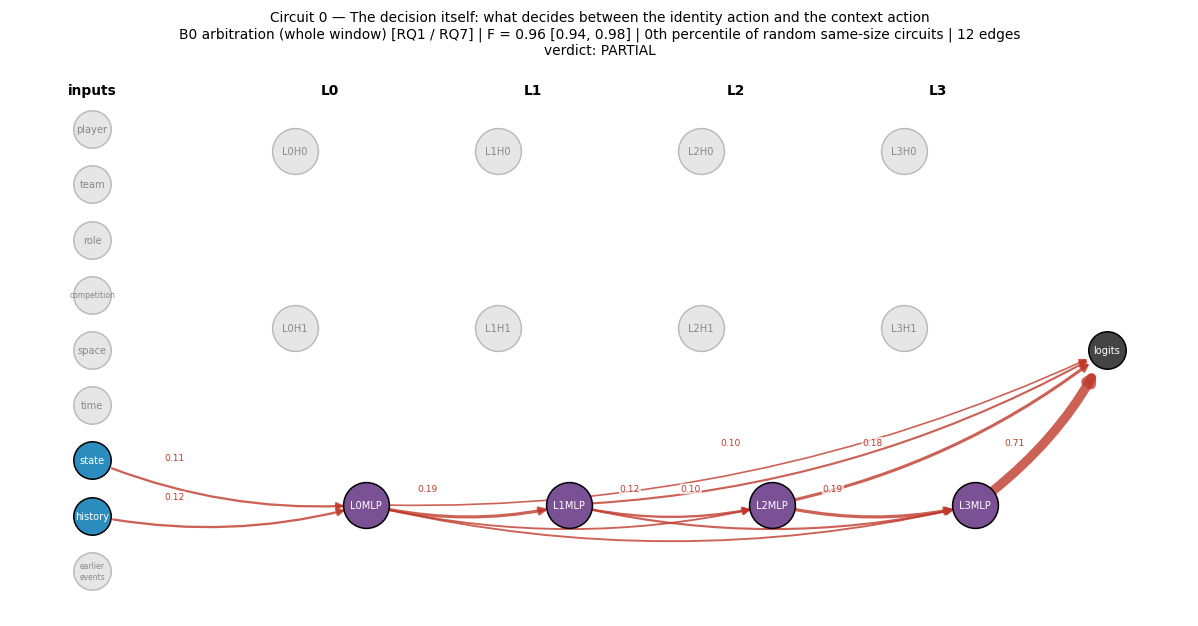

components in the circuit: L0MLP+L1MLP+L2MLP+L3MLP
faithfulness F = 0.957 [0.939, 0.978] | share kept when the circuit is removed: 0.008
edges replicating on held-out events: 100%
verdict: PARTIAL
        sender receiver  discovery R     R  CI low  CI high  replicates
         L3MLP   logits        0.721 0.707   0.687    0.721        True
         L2MLP    L3MLP        0.205 0.194   0.178    0.212        True
         L0MLP    L1MLP        0.178 0.186   0.141    0.236        True
         L2MLP   logits        0.168 0.179   0.170    0.189        True
         L1MLP    L2MLP        0.132 0.120   0.099    0.139        True
factor_history    L0MLP        0.151 0.116   0.075    0.165        True
  factor_state    L0MLP        0.127 0.113   0.089    0.136        True
         L1MLP   logits        0.093 0.103   0.086    0.119        True
         L1MLP    L3MLP        0.104 0.101   0.081    0.123        True
         L0MLP    L3MLP        0.091 0.082   0.073    0.096        True
         L0

In [12]:
show_circuit('B0 arbitration (whole window)')

### Circuit 1 — The influence of identity: how the player's identity reaches the decision

| | |
|---|---|
| **Sub-question** | RQ4 |
| **What is changed** | the acting player is removed (index 0) |
| **What the circuit shows** | where the player's identity enters, which heads and MLPs carry it, and where it reaches the output |

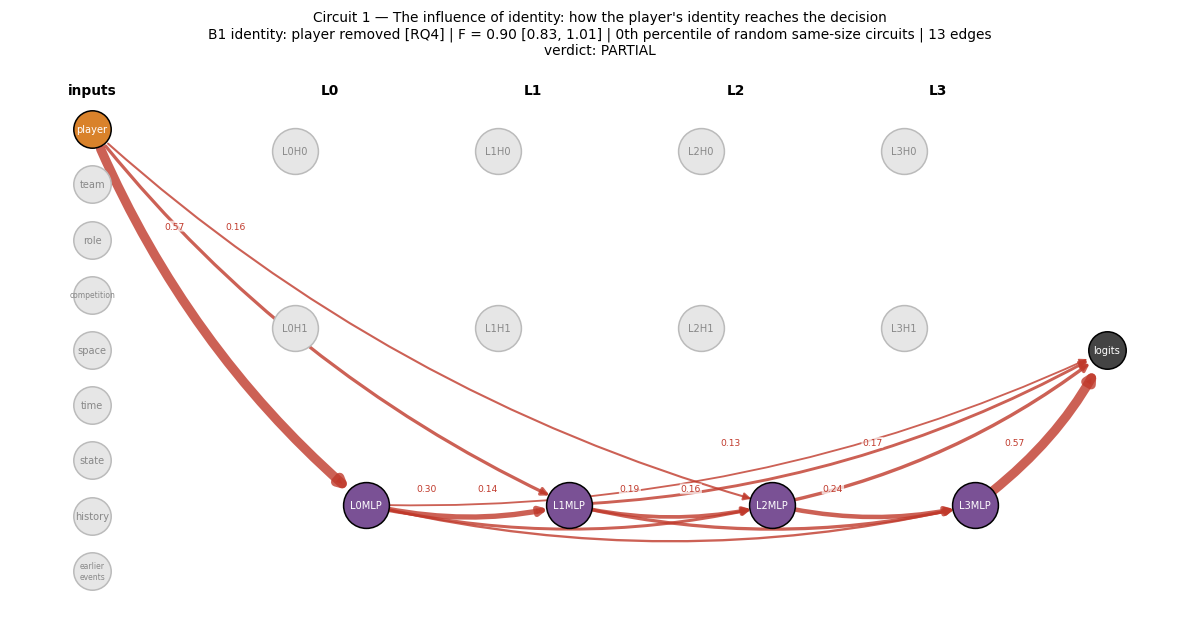

components in the circuit: L0MLP+L1MLP+L2MLP+L3MLP
faithfulness F = 0.901 [0.831, 1.012] | share kept when the circuit is removed: 0.006
edges replicating on held-out events: 100%
verdict: PARTIAL
       sender receiver  discovery R     R  CI low  CI high  replicates
        L3MLP   logits        0.577 0.572   0.549    0.598        True
factor_player    L0MLP        0.588 0.570   0.503    0.631        True
        L0MLP    L1MLP        0.332 0.300   0.244    0.334        True
        L2MLP    L3MLP        0.241 0.244   0.221    0.272        True
        L1MLP    L2MLP        0.216 0.188   0.152    0.222        True
        L2MLP   logits        0.179 0.169   0.153    0.196        True
        L1MLP    L3MLP        0.193 0.160   0.128    0.189        True
factor_player    L1MLP        0.176 0.156   0.124    0.186        True
        L0MLP    L2MLP        0.141 0.140   0.101    0.178        True
        L1MLP   logits        0.123 0.135   0.110    0.150        True
        L0MLP    L3MLP

In [13]:
show_circuit('B1 identity: player removed')

### Circuit 2 — The influence of which player it is

| | |
|---|---|
| **Sub-question** | RQ2 |
| **What is changed** | the acting player is swapped for a matched partner (same role, similar number of training events) |
| **What the circuit shows** | whether swapping one real player for another uses the same route as removing the player |

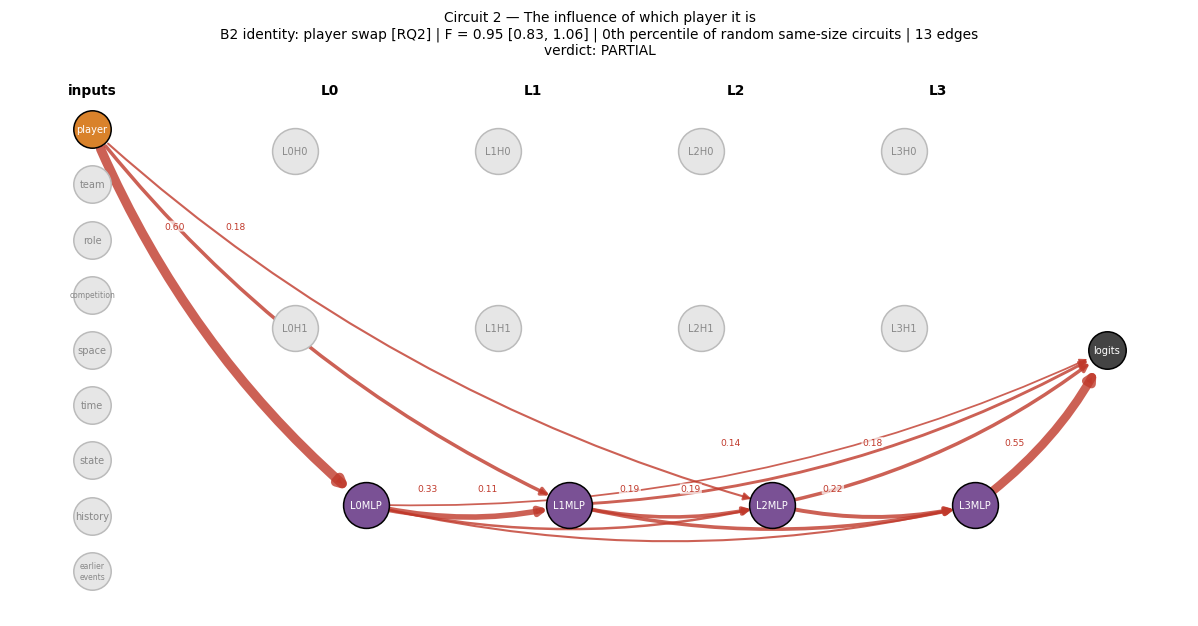

components in the circuit: L0MLP+L1MLP+L2MLP+L3MLP
faithfulness F = 0.947 [0.827, 1.058] | share kept when the circuit is removed: 0.011
edges replicating on held-out events: 100%
verdict: PARTIAL
       sender receiver  discovery R     R  CI low  CI high  replicates
factor_player    L0MLP        0.556 0.597   0.486    0.702        True
        L3MLP   logits        0.588 0.546   0.519    0.586        True
        L0MLP    L1MLP        0.309 0.330   0.264    0.383        True
        L2MLP    L3MLP        0.247 0.215   0.191    0.247        True
        L1MLP    L3MLP        0.209 0.191   0.171    0.214        True
        L1MLP    L2MLP        0.210 0.188   0.158    0.216        True
factor_player    L1MLP        0.201 0.183   0.141    0.238        True
        L2MLP   logits        0.179 0.183   0.158    0.203        True
        L1MLP   logits        0.119 0.140   0.107    0.172        True
        L0MLP    L2MLP        0.138 0.111   0.080    0.143        True
factor_player    L2MLP

In [14]:
show_circuit('B2 identity: player swap')

### Circuit 3 — The influence of the player beyond their role

| | |
|---|---|
| **Sub-question** | RQ2 / audit N1 |
| **What is changed** | the player's vector is replaced by the average vector of players in the same role |
| **What the circuit shows** | the route of what is specific to this player, with what all players of the role share held fixed |

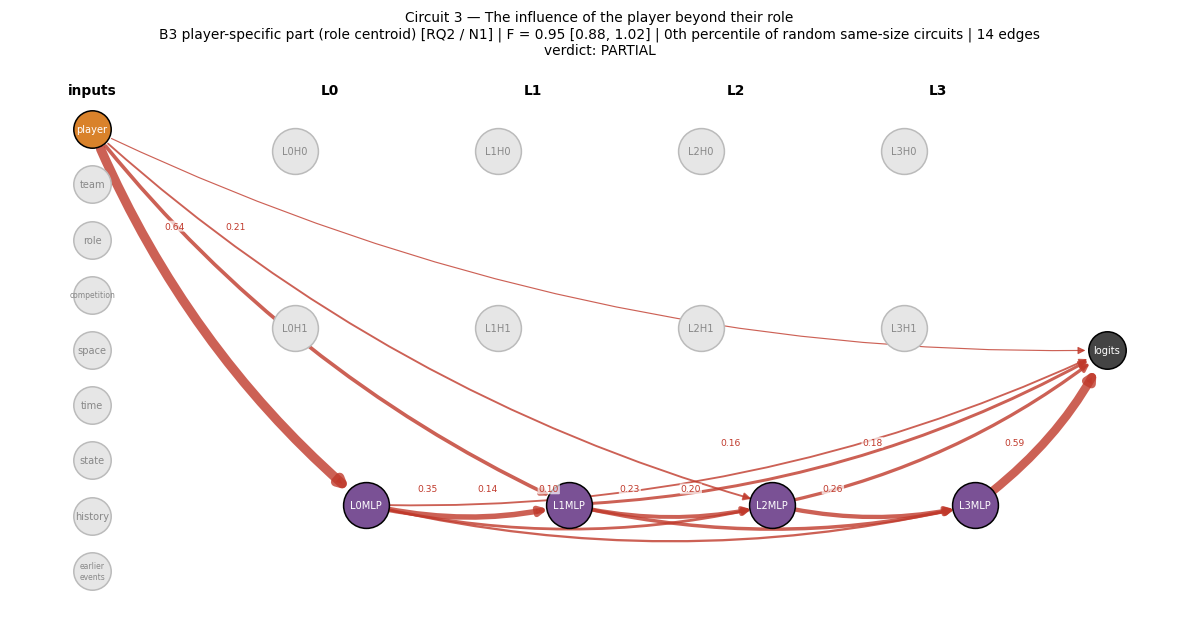

components in the circuit: L0MLP+L1MLP+L2MLP+L3MLP
faithfulness F = 0.949 [0.881, 1.023] | share kept when the circuit is removed: 0.003
edges replicating on held-out events: 100%
verdict: PARTIAL
       sender receiver  discovery R     R  CI low  CI high  replicates
factor_player    L0MLP        0.571 0.641   0.564    0.692        True
        L3MLP   logits        0.576 0.586   0.563    0.613        True
        L0MLP    L1MLP        0.303 0.349   0.304    0.380        True
        L2MLP    L3MLP        0.217 0.259   0.242    0.277        True
        L1MLP    L2MLP        0.180 0.230   0.183    0.275        True
factor_player    L1MLP        0.185 0.210   0.163    0.262        True
        L1MLP    L3MLP        0.205 0.196   0.173    0.227        True
        L2MLP   logits        0.151 0.180   0.162    0.198        True
        L1MLP   logits        0.126 0.158   0.131    0.175        True
        L0MLP    L2MLP        0.132 0.141   0.118    0.156        True
        L0MLP    L3MLP

In [15]:
show_circuit('B3 player-specific part (role centroid)')

### Circuit 4 — The influence of the player's role

| | |
|---|---|
| **Sub-question** | RQ2 / RQ3 |
| **What is changed** | the role input is changed to another role |
| **What the circuit shows** | the route of the role signal, to compare with the player's route (Circuits 1–3) |

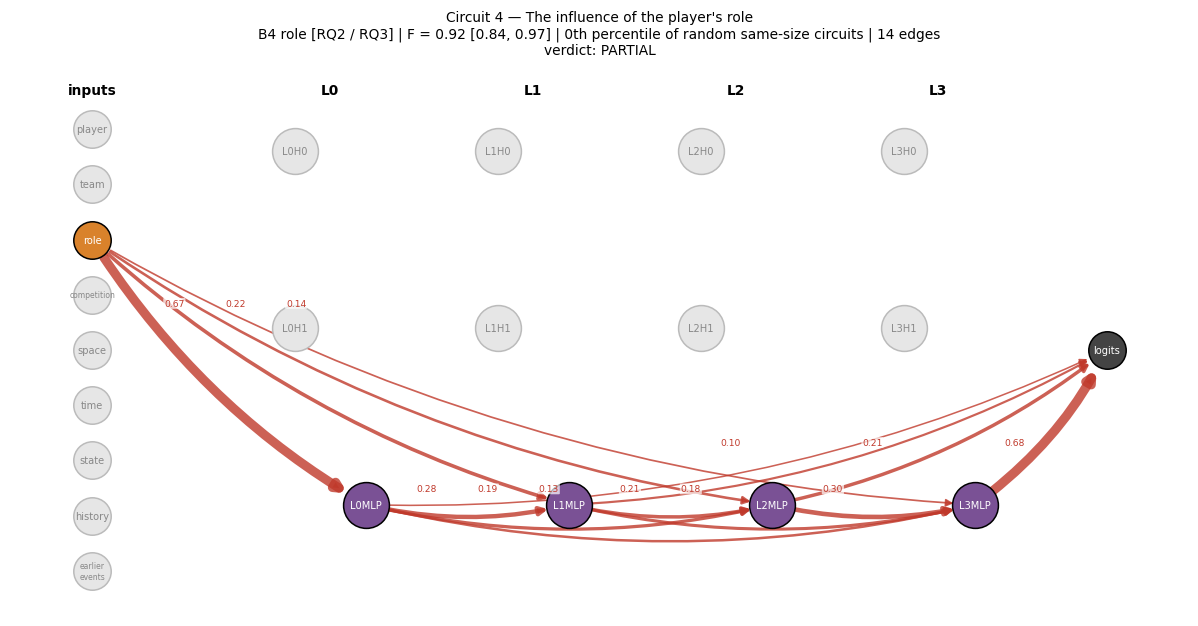

components in the circuit: L0MLP+L1MLP+L2MLP+L3MLP
faithfulness F = 0.915 [0.844, 0.973] | share kept when the circuit is removed: 0.007
edges replicating on held-out events: 100%
verdict: PARTIAL
     sender receiver  discovery R     R  CI low  CI high  replicates
      L3MLP   logits        0.679 0.684   0.593    0.757        True
factor_role    L0MLP        0.662 0.667   0.575    0.732        True
      L2MLP    L3MLP        0.313 0.300   0.213    0.369        True
      L0MLP    L1MLP        0.284 0.283   0.238    0.345        True
factor_role    L1MLP        0.221 0.219   0.141    0.293        True
      L1MLP    L2MLP        0.203 0.210   0.138    0.282        True
      L2MLP   logits        0.207 0.206   0.179    0.243        True
      L0MLP    L2MLP        0.195 0.190   0.158    0.232        True
      L1MLP    L3MLP        0.182 0.177   0.147    0.202        True
factor_role    L2MLP        0.155 0.137   0.100    0.181        True
      L0MLP    L3MLP        0.144 0.130   0.

In [16]:
show_circuit('B4 role')

### Circuit 5 — The influence of context: how the game situation reaches the decision

| | |
|---|---|
| **Sub-question** | RQ5 |
| **What is changed** | the window is replaced by the donor's, with the event's own player, team, role and competition written back |
| **What the circuit shows** | where the situation enters (scored event or earlier events), which heads and MLPs carry it, and where it reaches the output |

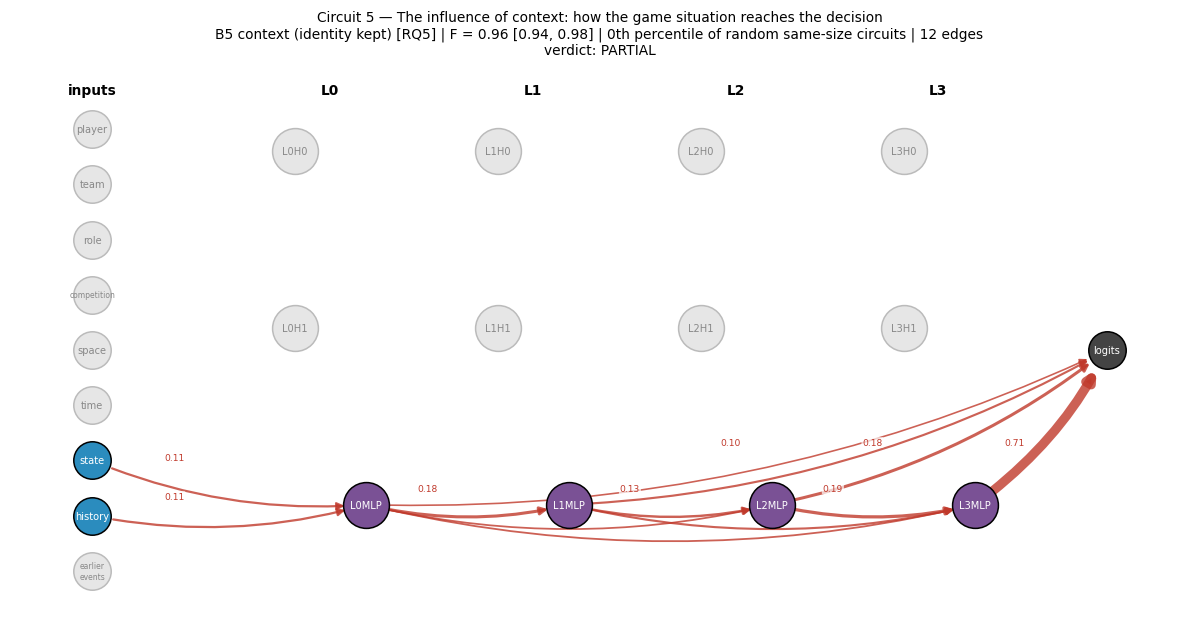

components in the circuit: L0MLP+L1MLP+L2MLP+L3MLP
faithfulness F = 0.955 [0.937, 0.978] | share kept when the circuit is removed: 0.007
edges replicating on held-out events: 100%
verdict: PARTIAL
        sender receiver  discovery R     R  CI low  CI high  replicates
         L3MLP   logits        0.720 0.707   0.683    0.726        True
         L2MLP    L3MLP        0.205 0.193   0.176    0.209        True
         L0MLP    L1MLP        0.186 0.181   0.136    0.232        True
         L2MLP   logits        0.169 0.177   0.167    0.187        True
         L1MLP    L2MLP        0.132 0.126   0.109    0.147        True
factor_history    L0MLP        0.154 0.112   0.077    0.148        True
  factor_state    L0MLP        0.131 0.110   0.085    0.126        True
         L1MLP   logits        0.094 0.103   0.089    0.115        True
         L1MLP    L3MLP        0.102 0.100   0.074    0.127        True
         L0MLP    L3MLP        0.089 0.075   0.067    0.087        True
         L0

In [17]:
show_circuit('B5 context (identity kept)')

### Circuit 6 — The influence of the previous action

| | |
|---|---|
| **Sub-question** | RQ3 |
| **What is changed** | only the previous-action input at the scored event takes the donor's value |
| **What the circuit shows** | the route of the single context input MB13 found most important |

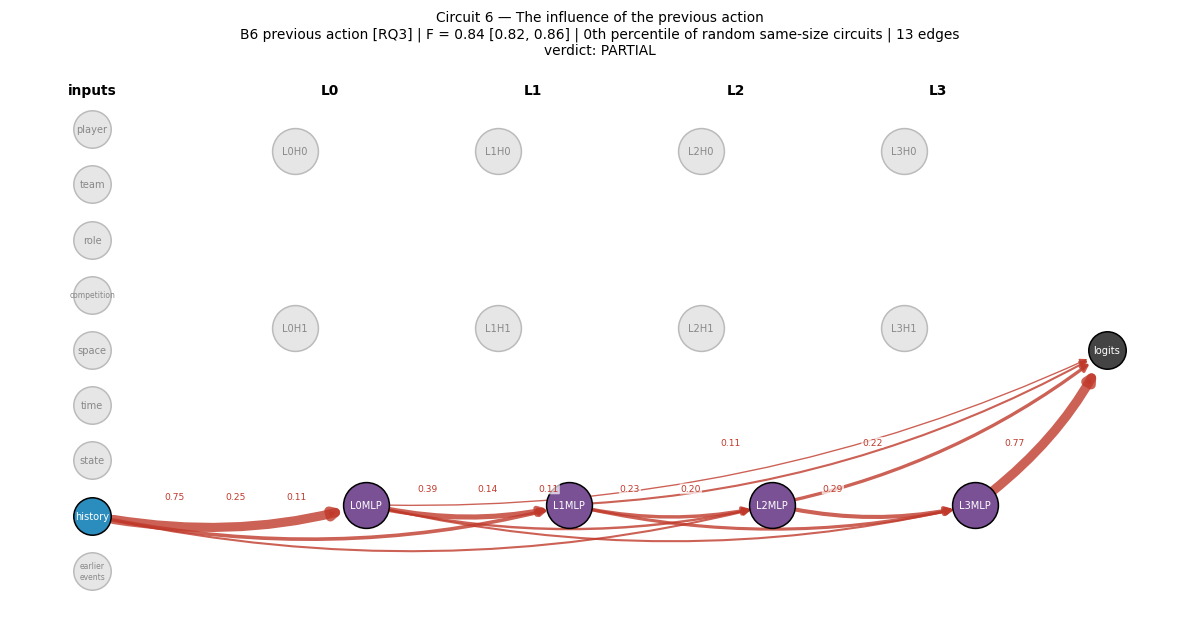

components in the circuit: L0MLP+L1MLP+L2MLP+L3MLP
faithfulness F = 0.840 [0.818, 0.859] | share kept when the circuit is removed: 0.002
edges replicating on held-out events: 100%
verdict: PARTIAL
        sender receiver  discovery R     R  CI low  CI high  replicates
         L3MLP   logits        0.785 0.770   0.755    0.786        True
factor_history    L0MLP        0.759 0.755   0.729    0.775        True
         L0MLP    L1MLP        0.365 0.389   0.351    0.438        True
         L2MLP    L3MLP        0.291 0.291   0.267    0.315        True
factor_history    L1MLP        0.222 0.250   0.233    0.271        True
         L1MLP    L2MLP        0.211 0.231   0.203    0.266        True
         L2MLP   logits        0.213 0.217   0.198    0.237        True
         L1MLP    L3MLP        0.188 0.202   0.184    0.222        True
         L0MLP    L2MLP        0.138 0.138   0.125    0.150        True
         L1MLP   logits        0.107 0.109   0.097    0.120        True
factor_hist

In [18]:
show_circuit('B6 previous action')

### Circuit 7 — The influence of a change of possession

| | |
|---|---|
| **Sub-question** | RQ3 |
| **What is changed** | only the possession-change input at the scored event takes the donor's value |
| **What the circuit shows** | the route of the possession-change signal |

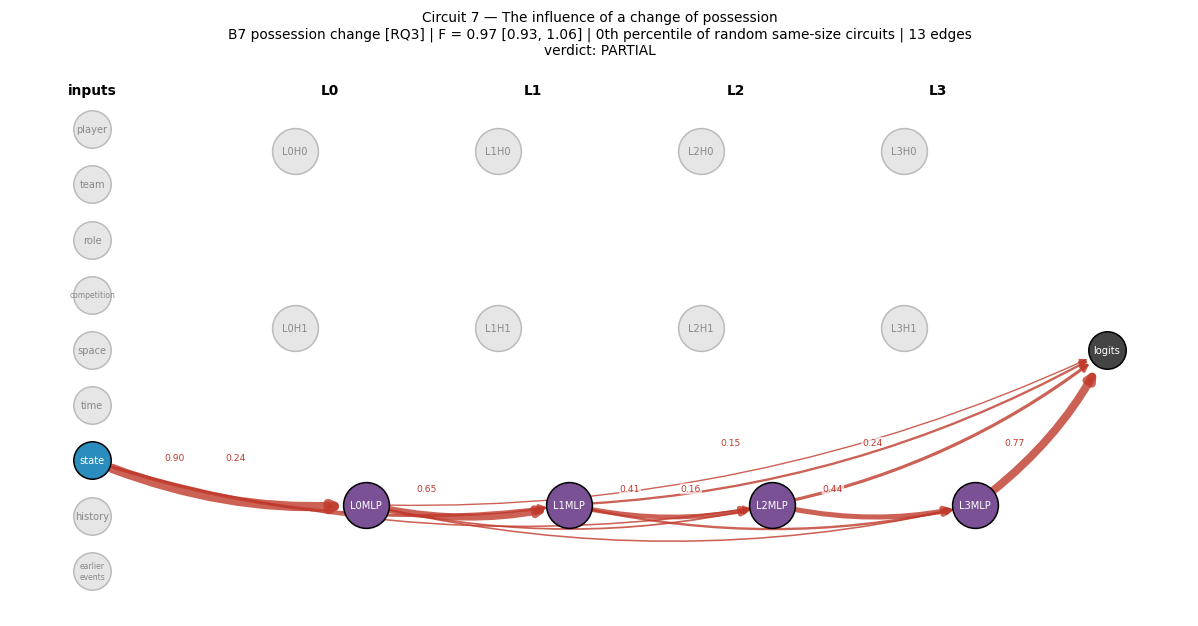

components in the circuit: L0MLP+L1MLP+L2MLP+L3MLP
faithfulness F = 0.972 [0.928, 1.056] | share kept when the circuit is removed: 0.003
edges replicating on held-out events: 100%
verdict: PARTIAL
      sender receiver  discovery R     R  CI low  CI high  replicates
factor_state    L0MLP        0.913 0.898   0.855    0.945        True
       L3MLP   logits        0.764 0.767   0.740    0.798        True
       L0MLP    L1MLP        0.641 0.646   0.586    0.709        True
       L2MLP    L3MLP        0.452 0.443   0.397    0.511        True
       L1MLP    L2MLP        0.435 0.409   0.361    0.468        True
       L2MLP   logits        0.251 0.241   0.226    0.267        True
factor_state    L1MLP        0.247 0.235   0.201    0.272        True
       L1MLP    L3MLP        0.155 0.157   0.115    0.179        True
       L1MLP   logits        0.145 0.151   0.137    0.161        True
       L0MLP    L2MLP        0.118 0.090   0.069    0.118        True
       L0MLP    L3MLP        0.09

In [19]:
show_circuit('B7 possession change')

### Circuit 8 — The influence of the time since the previous event

| | |
|---|---|
| **Sub-question** | RQ3 |
| **What is changed** | only the time-gap input at the scored event takes the donor's value |
| **What the circuit shows** | the route of the time-gap signal |

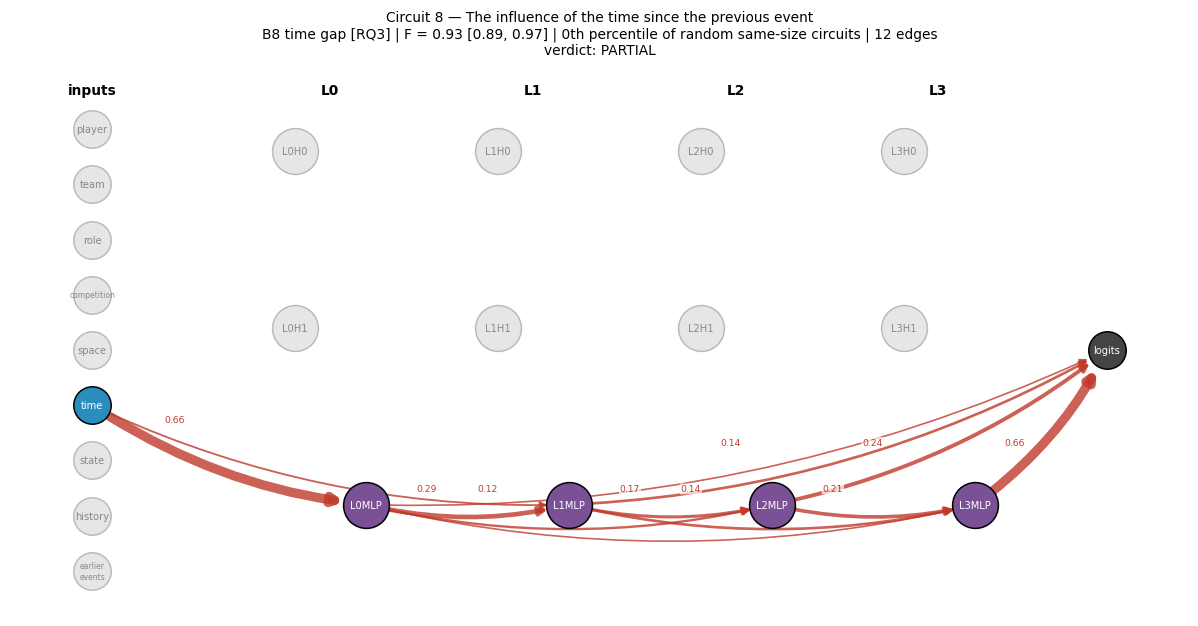

components in the circuit: L0MLP+L1MLP+L2MLP+L3MLP
faithfulness F = 0.929 [0.888, 0.971] | share kept when the circuit is removed: 0.011
edges replicating on held-out events: 100%
verdict: PARTIAL
     sender receiver  discovery R     R  CI low  CI high  replicates
factor_time    L0MLP        0.658 0.664   0.623    0.725        True
      L3MLP   logits        0.663 0.662   0.641    0.678        True
      L0MLP    L1MLP        0.242 0.295   0.245    0.349        True
      L2MLP   logits        0.226 0.235   0.218    0.253        True
      L2MLP    L3MLP        0.198 0.215   0.194    0.232        True
      L1MLP    L2MLP        0.174 0.171   0.133    0.213        True
      L1MLP    L3MLP        0.111 0.139   0.109    0.172        True
      L1MLP   logits        0.116 0.138   0.120    0.156        True
      L0MLP    L2MLP        0.120 0.116   0.083    0.144        True
factor_time    L1MLP        0.068 0.074   0.057    0.097        True
      L0MLP   logits        0.072 0.057   0.

In [20]:
show_circuit('B8 time gap')

### Circuit 9 — The interaction of identity and context: where the situation changes how much the player matters

| | |
|---|---|
| **Sub-question** | RQ7 |
| **What is changed** | the metric is the identity effect (Δ with the player minus Δ without); clean = own window, corrupted = donor window with identity kept |
| **What the circuit shows** | the connections through which the context changes the player's effect: the place where identity and context meet |

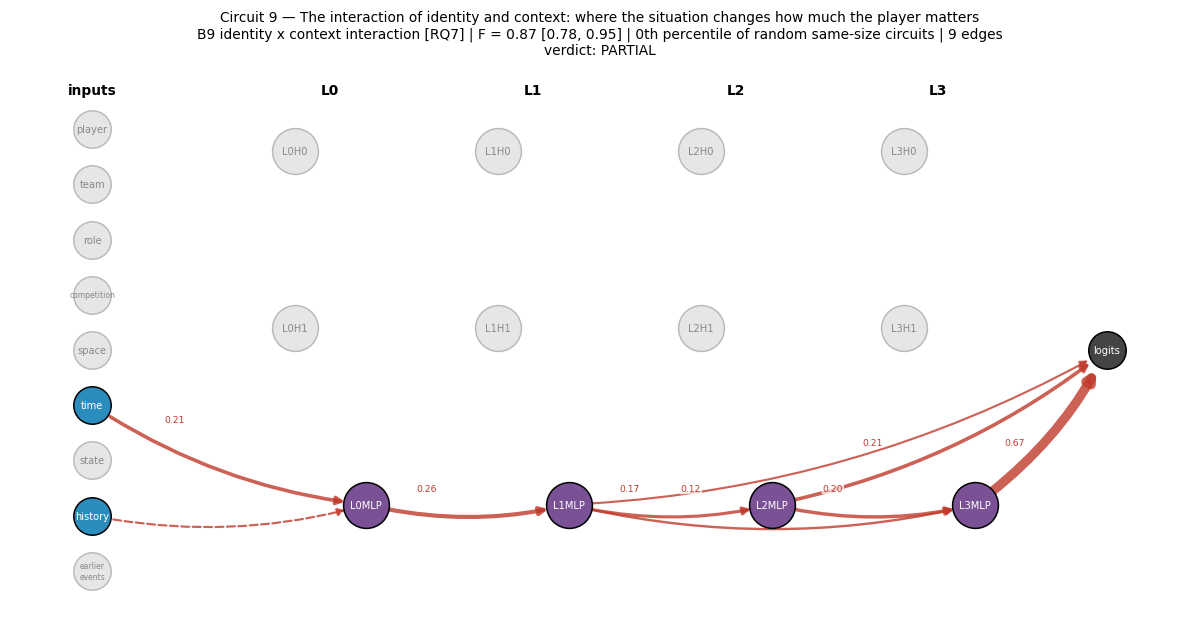

components in the circuit: L0MLP+L1MLP+L2MLP+L3MLP
faithfulness F = 0.868 [0.781, 0.946] | share kept when the circuit is removed: -0.003
edges replicating on held-out events: 89%
verdict: PARTIAL
        sender receiver  discovery R     R  CI low  CI high  replicates
         L3MLP   logits        0.712 0.668   0.643    0.704        True
         L0MLP    L1MLP        0.232 0.257   0.141    0.357        True
   factor_time    L0MLP        0.135 0.214   0.168    0.298        True
         L2MLP   logits        0.197 0.213   0.189    0.237        True
         L2MLP    L3MLP        0.177 0.198   0.139    0.284        True
         L1MLP    L2MLP        0.166 0.174   0.067    0.252        True
         L1MLP    L3MLP        0.094 0.117   0.073    0.169        True
factor_history    L0MLP        0.117 0.098  -0.022    0.263       False
         L1MLP   logits        0.075 0.096   0.080    0.109        True


In [21]:
show_circuit('B9 identity x context interaction')

### Circuit 10 — The influence of identity on the player's own characteristic action

| | |
|---|---|
| **Sub-question** | audit N3 |
| **What is changed** | as Circuit 1, but Δ′ = logit(a_ctx) − logit(a_lift), where a_lift is the action this player's identity raises most above the base rate |
| **What the circuit shows** | whether the identity route is the same when the identity side is the player's typical action rather than the default pass |

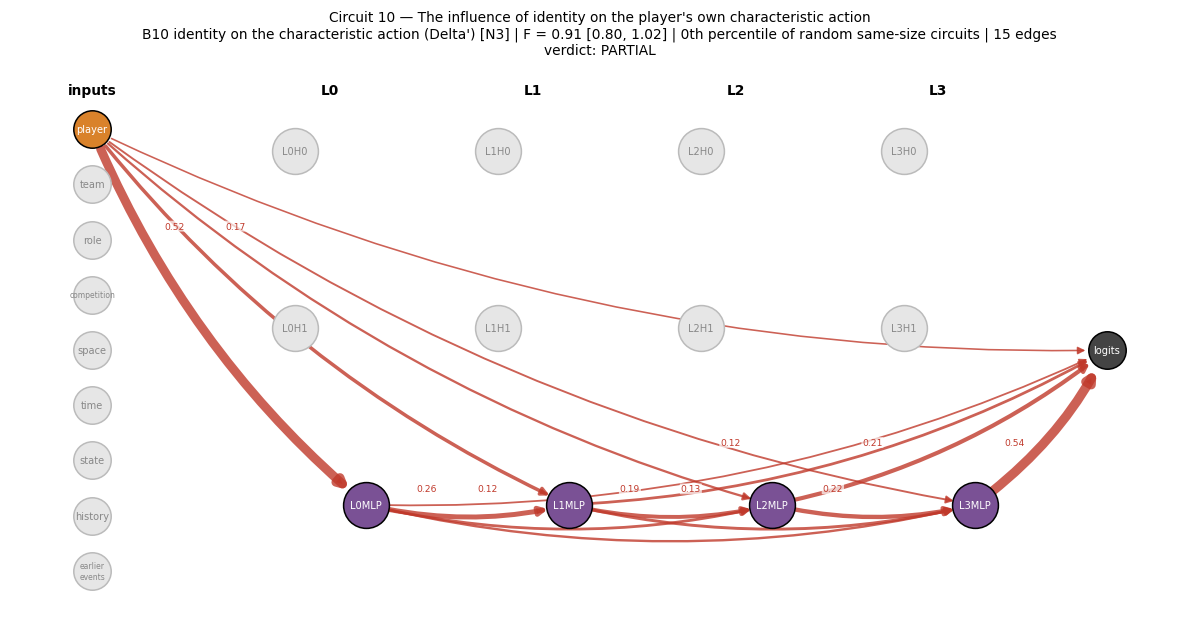

components in the circuit: L0MLP+L1MLP+L2MLP+L3MLP
faithfulness F = 0.914 [0.804, 1.015] | share kept when the circuit is removed: 0.011
edges replicating on held-out events: 100%
verdict: PARTIAL
       sender receiver  discovery R     R  CI low  CI high  replicates
        L3MLP   logits        0.551 0.539   0.489    0.598        True
factor_player    L0MLP        0.551 0.515   0.428    0.576        True
        L0MLP    L1MLP        0.267 0.260   0.185    0.313        True
        L2MLP    L3MLP        0.231 0.220   0.197    0.251        True
        L2MLP   logits        0.183 0.207   0.186    0.231        True
        L1MLP    L2MLP        0.182 0.193   0.157    0.225        True
factor_player    L1MLP        0.155 0.166   0.138    0.194        True
        L1MLP    L3MLP        0.152 0.130   0.103    0.160        True
        L0MLP    L2MLP        0.148 0.120   0.092    0.148        True
        L1MLP   logits        0.115 0.118   0.095    0.137        True
        L0MLP    L3MLP

In [22]:
show_circuit("B10 identity on the characteristic action (Delta')")

## 9. Comparing the circuits

### Identity's circuit vs context's circuit

Circuit 1 (identity) and Circuit 5 (context) on one diagram. **Orange** = connection only in the identity circuit, **blue** = only in the context circuit, **purple** = in both. Connections are compared at the level of components (which head or MLP sends to which), so the different input nodes (player vs context inputs) do not count as a difference by themselves.

If identity and context used separate pathways, the drawing would be mostly orange and blue. If they share one pathway, it would be mostly purple.

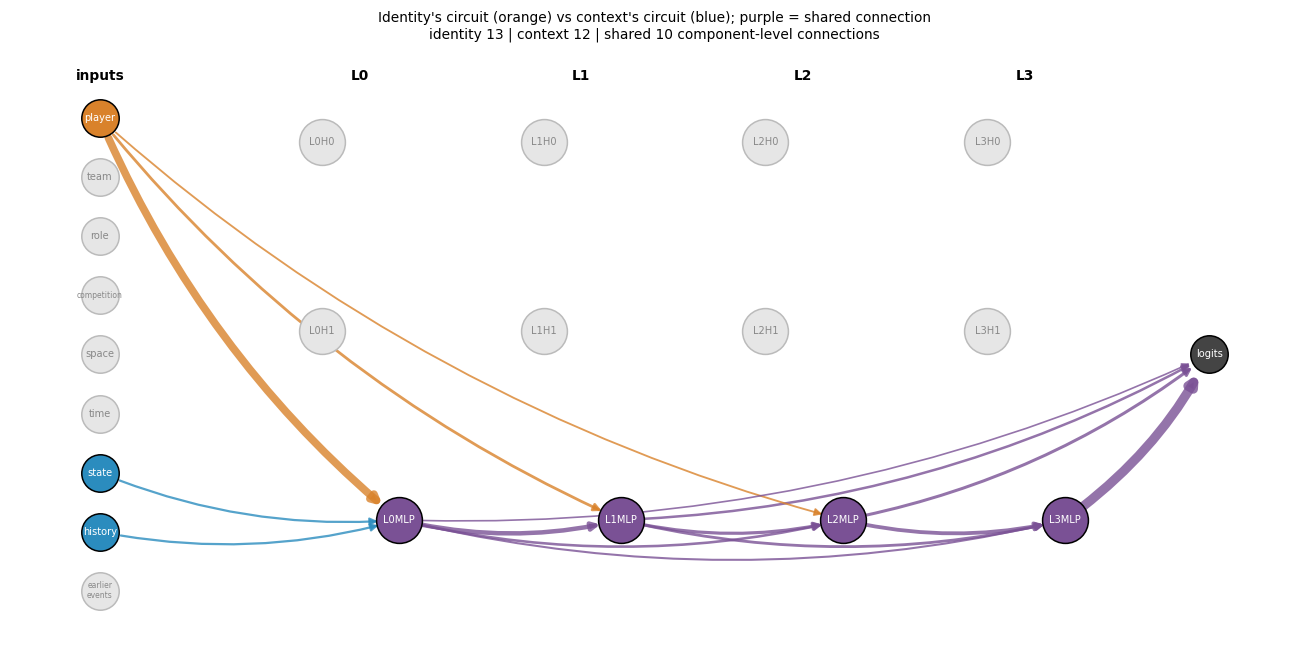

shared connections: [('L0MLP', 'L1MLP'), ('L0MLP', 'L2MLP'), ('L0MLP', 'L3MLP'), ('L0MLP', 'logits'), ('L1MLP', 'L2MLP'), ('L1MLP', 'L3MLP'), ('L1MLP', 'logits'), ('L2MLP', 'L3MLP'), ('L2MLP', 'logits'), ('L3MLP', 'logits')]
identity only: [('factor_player', 'L0MLP'), ('factor_player', 'L1MLP'), ('factor_player', 'L2MLP')]
context only: [('factor_history', 'L0MLP'), ('factor_state', 'L0MLP')]


In [23]:
def edge_set(name):
    est = ATLAS.get(name, {}).get("estimation", pd.DataFrame())
    return set(zip(est["sender"], est["receiver"])) if len(est) else set()


def component_pair(edge):
    return (node_of(edge[0]), node_of(edge[1]))


identity_name, context_name, interaction_name = "B1 identity: player removed", "B5 context (identity kept)", "B9 identity x context interaction"
if identity_name in ATLAS and context_name in ATLAS:
    ident, ctx = ATLAS[identity_name]["estimation"], ATLAS[context_name]["estimation"]
    id_pairs = {component_pair(e) for e in edge_set(identity_name)}
    ctx_pairs = {component_pair(e) for e in edge_set(context_name)}
    combined = pd.concat([ident.assign(source="identity"), ctx.assign(source="context")], ignore_index=True)
    combined["pair"] = [component_pair((s, r)) for s, r in zip(combined["sender"], combined["receiver"])]
    combined = combined.sort_values("R", key=np.abs, ascending=False).drop_duplicates("pair")
    colour = lambda row: "#7a5195" if (row["pair"] in id_pairs and row["pair"] in ctx_pairs) else (
        IDENTITY_COLOUR if row["pair"] in id_pairs else CONTEXT_COLOUR)
    shared = id_pairs & ctx_pairs
    fig, axis = plt.subplots(figsize=(12, 6))
    draw_circuit(axis, combined, "Identity's circuit (orange) vs context's circuit (blue); purple = shared connection\n"
                                 f"identity {len(id_pairs)} | context {len(ctx_pairs)} | shared {len(shared)} component-level connections",
                 colour_of=colour, show_labels=False)
    plt.tight_layout(); plt.savefig(OUT / "figures" / "MB19_identity_vs_context.png", bbox_inches="tight", dpi=150); plt.show()
    print("shared connections:", sorted(shared))
    print("identity only:", sorted(id_pairs - ctx_pairs))
    print("context only:", sorted(ctx_pairs - id_pairs))
else:
    print("Circuit 1 or Circuit 5 was not run")

### Where identity and context meet: the interaction circuit next to both

Left to right: identity's circuit (1), context's circuit (5), and the interaction circuit (9). A component that appears in all three is a candidate place where the two signals are combined.

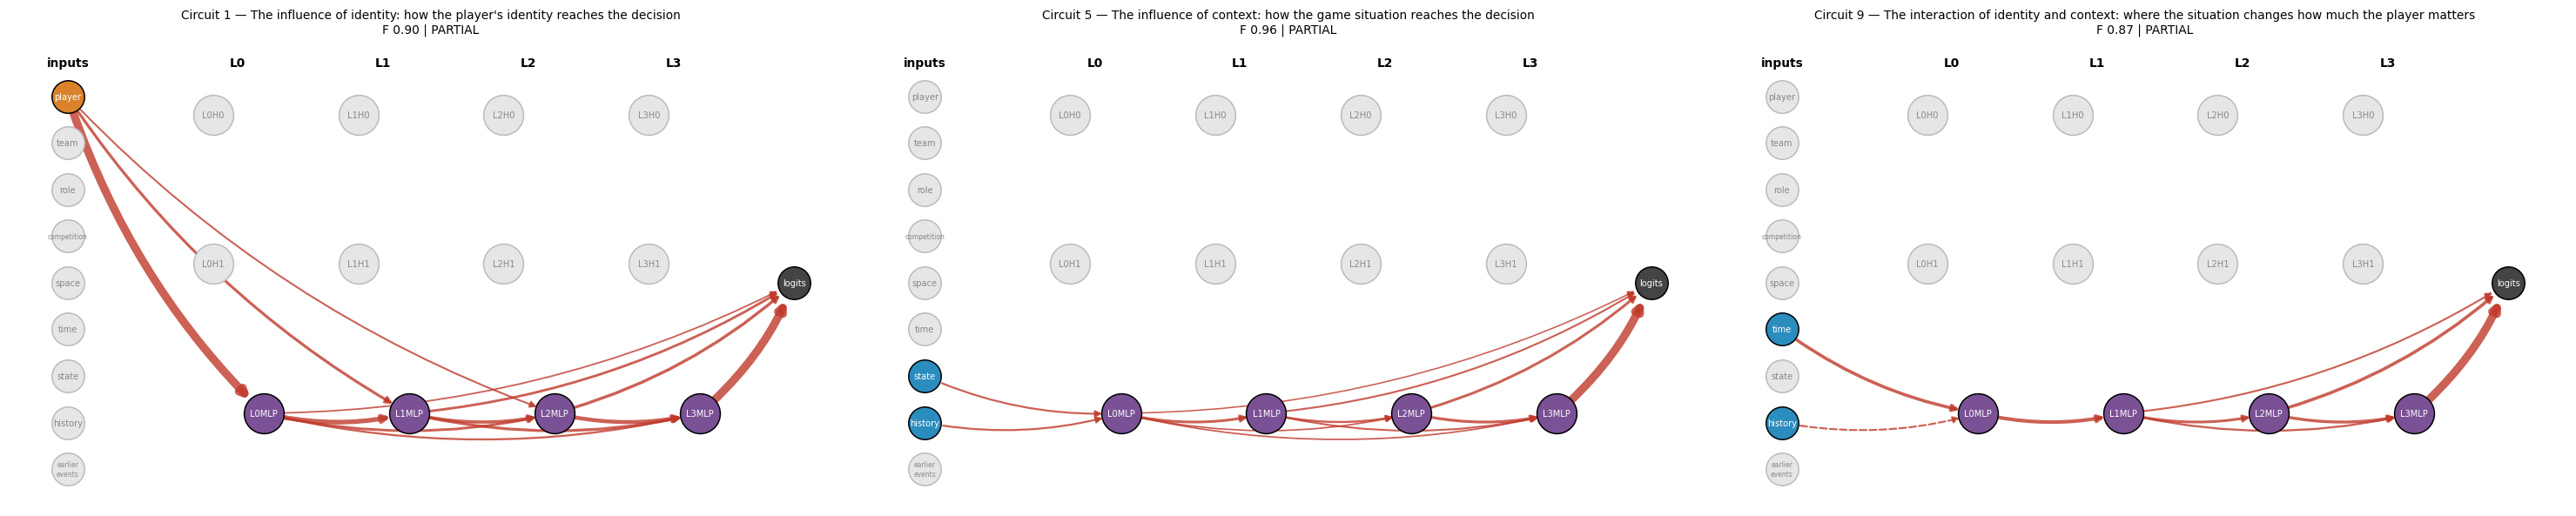

components in every one of these circuits (candidate meeting points): ['L0MLP', 'L1MLP', 'L2MLP', 'L3MLP']


In [24]:
present = [n for n in [identity_name, context_name, interaction_name] if n in ATLAS]
fig, axes = plt.subplots(1, len(present), figsize=(9 * len(present), 5.5), squeeze=False)
for axis, name in zip(axes[0], present):
    entry = ATLAS[name]
    draw_circuit(axis, entry["estimation"], f"{TITLES[name]}\nF {entry['F']['recovery']:.2f} | {entry['verdict']}", show_labels=False)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB19_where_identity_and_context_meet.png", bbox_inches="tight", dpi=130); plt.show()
in_all = set.intersection(*[set(ATLAS[n]["components"]) for n in present]) if present else set()
print("components in every one of these circuits (candidate meeting points):", sorted(in_all) or "none")

### How much do the circuits of the different sub-questions share?

Each cell is the overlap (Jaccard: shared connections / all connections of the two) between two circuits, at component level. 1 = identical routes, 0 = no connection in common.

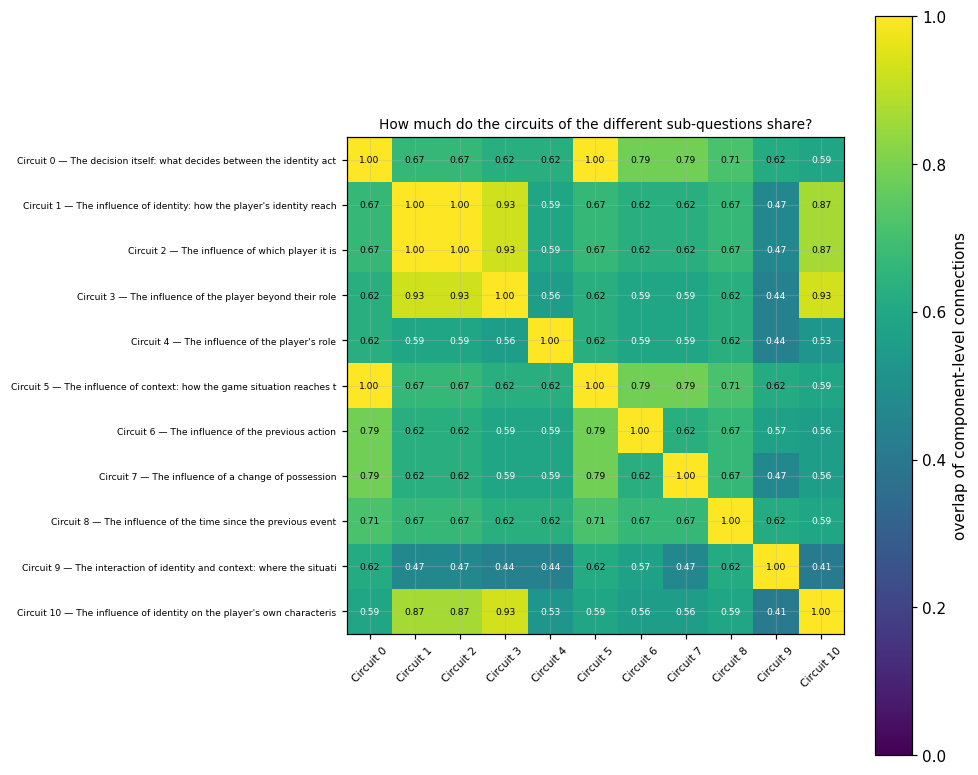

In [25]:
names = list(ATLAS)
pair_sets = {name: {component_pair(e) for e in edge_set(name)} for name in names}
jaccard = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        union = pair_sets[a] | pair_sets[b]
        jaccard.loc[a, b] = len(pair_sets[a] & pair_sets[b]) / len(union) if union else np.nan
jaccard.to_csv(OUT / "results" / "MB19_edge_overlap.csv")
fig, axis = plt.subplots(figsize=(9, 7.5))
image = axis.imshow(jaccard.to_numpy(dtype=float), vmin=0, vmax=1, cmap="viridis")
axis.set_xticks(range(len(names))); axis.set_xticklabels([TITLES[n].split(" — ")[0] for n in names], rotation=45, fontsize=7)
axis.set_yticks(range(len(names))); axis.set_yticklabels([TITLES[n] [:70] for n in names], fontsize=6)
for i in range(len(names)):
    for j in range(len(names)):
        value = jaccard.iloc[i, j]
        if np.isfinite(value):
            axis.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=6, color="white" if value < 0.6 else "black")
plt.colorbar(image, ax=axis, label="overlap of component-level connections")
axis.set_title("How much do the circuits of the different sub-questions share?", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB19_circuit_overlap.png", bbox_inches="tight", dpi=150); plt.show()

### All circuits on one page

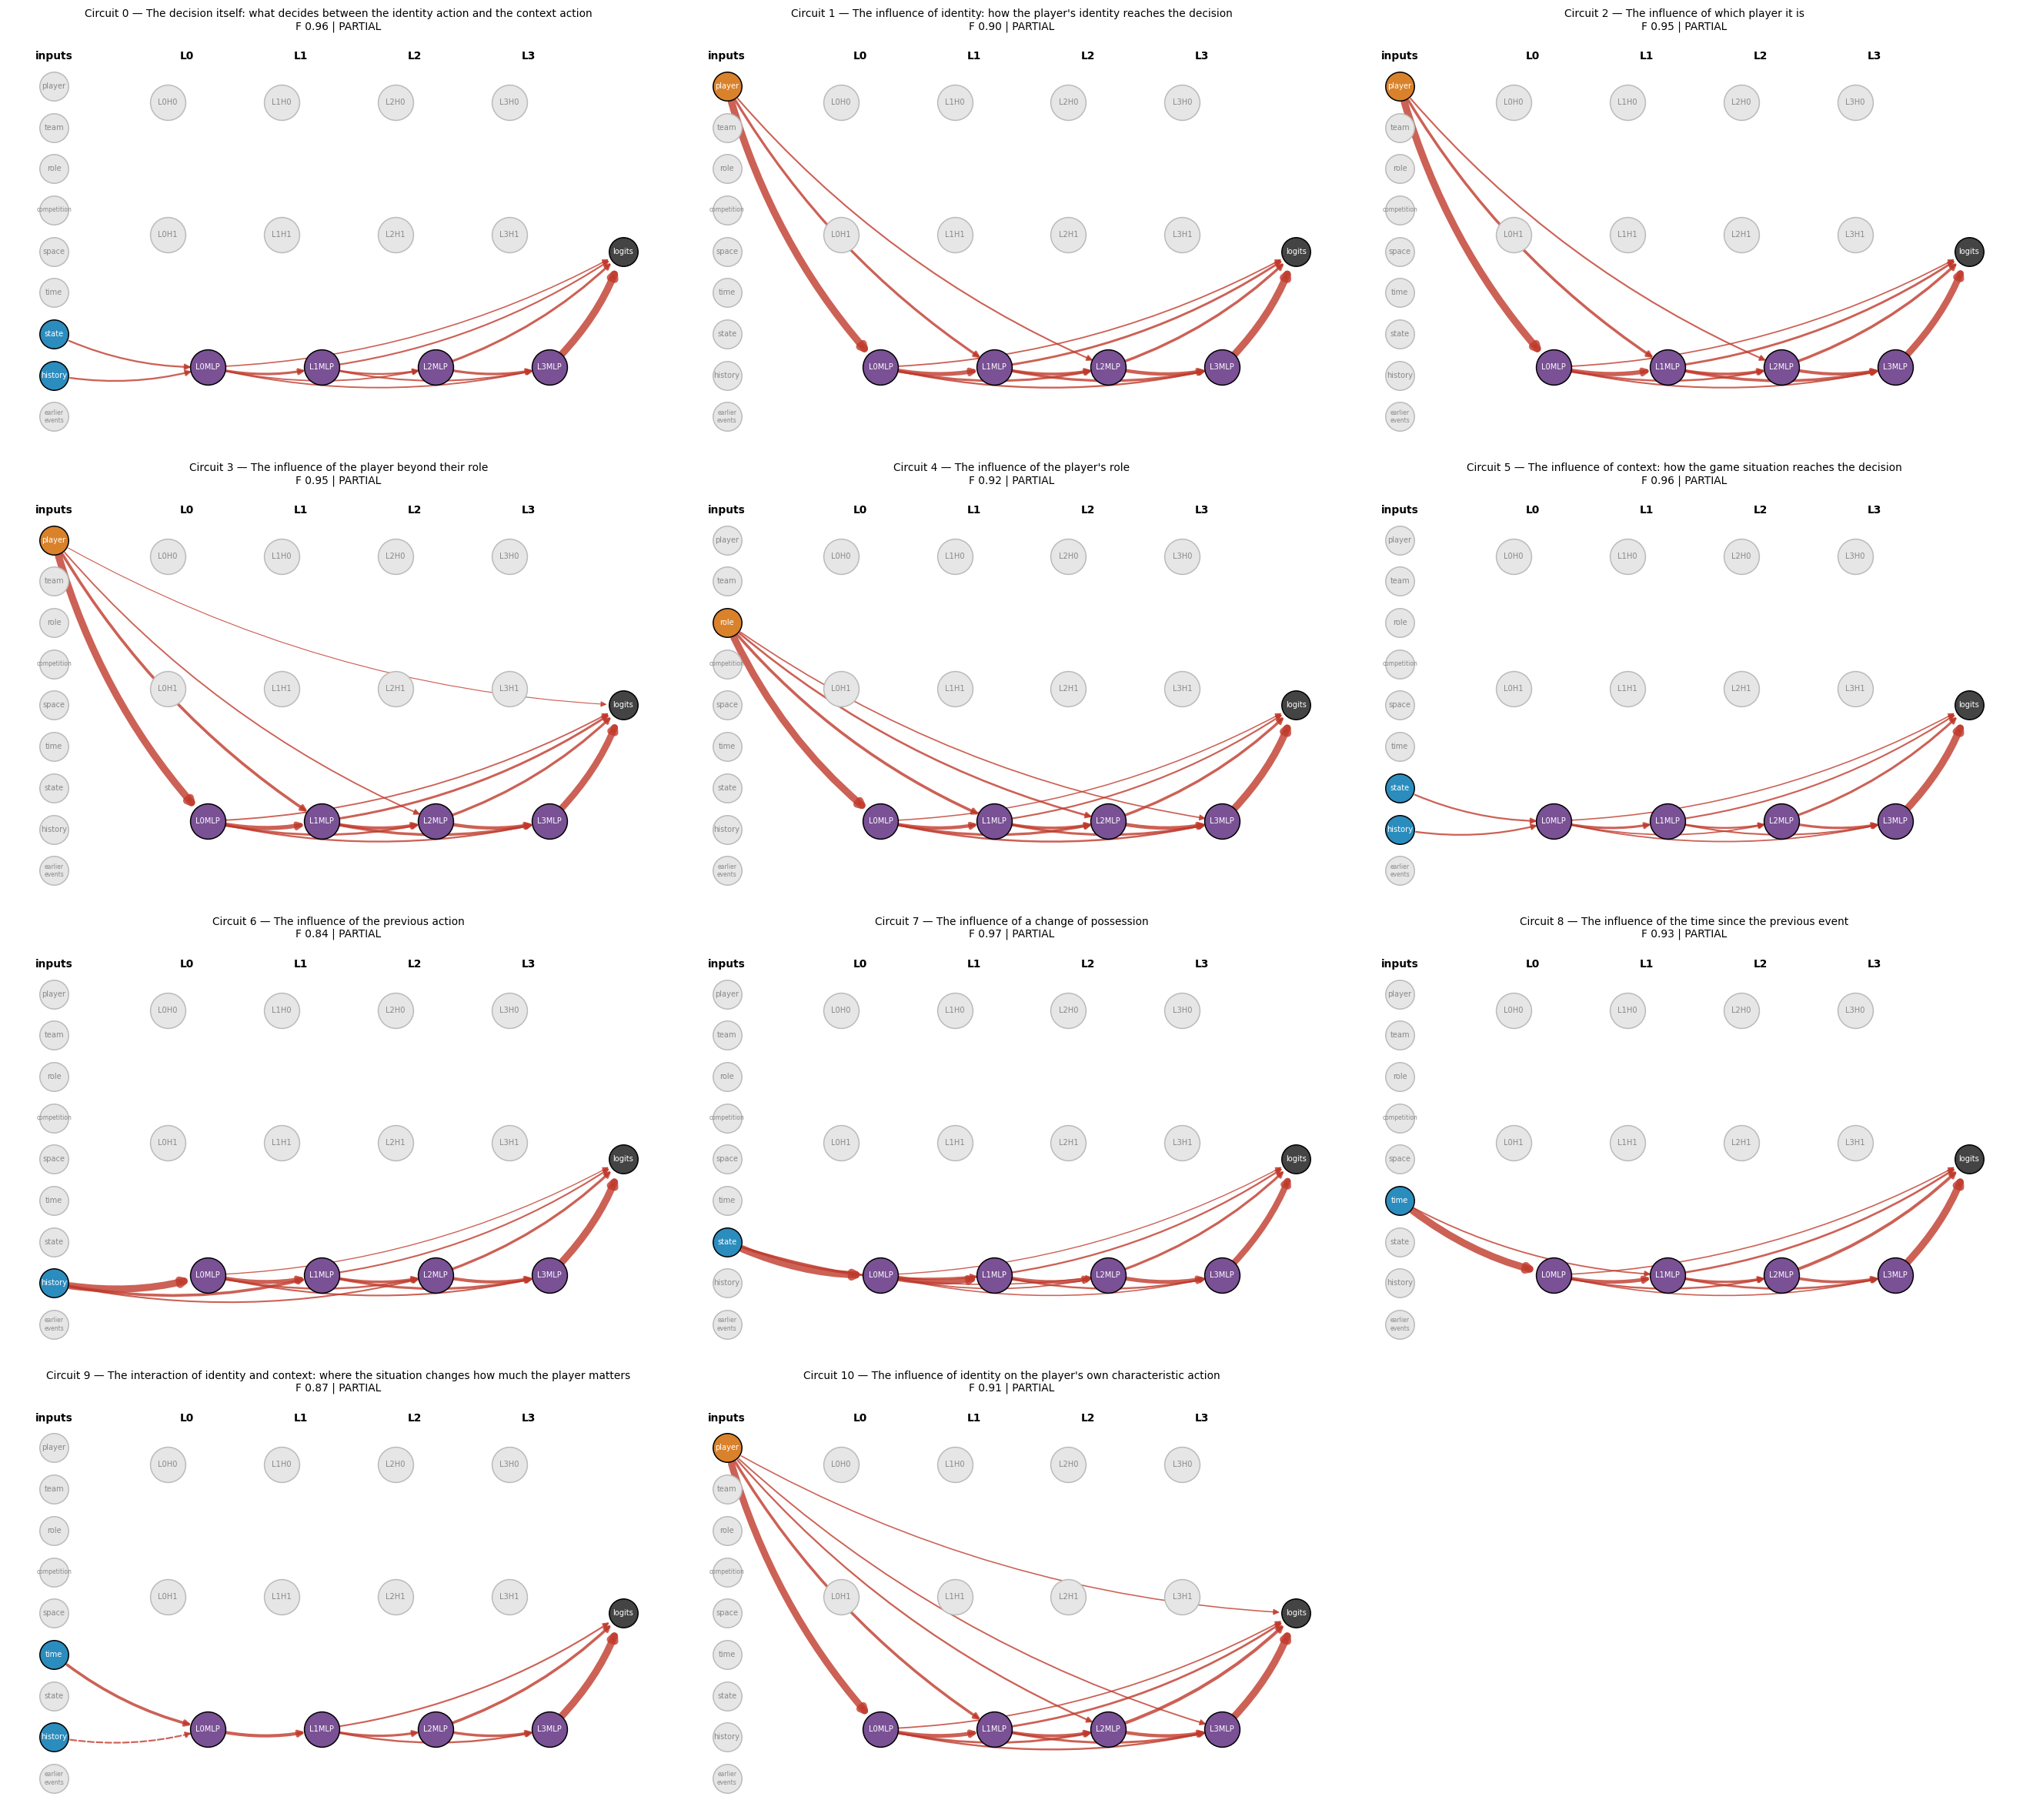

In [26]:
rows = int(np.ceil(len(names) / 3))
fig, axes = plt.subplots(rows, 3, figsize=(24, 5.4 * rows), squeeze=False)
for axis, name in zip(axes.flat, names):
    entry = ATLAS[name]
    draw_circuit(axis, entry["estimation"], f"{TITLES[name]}\nF {entry['F']['recovery']:.2f} | {entry['verdict']}", show_labels=False)
for axis in list(axes.flat)[len(names):]:
    axis.axis("off")
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB19_all_circuits.png", bbox_inches="tight", dpi=130); plt.show()

## 10. Which circuits can the paper report?

The verdict column applies the plan's rule. Only MEANINGFUL circuits should be drawn in the paper as circuits; PARTIAL ones can be shown with their caveat (for example "faithful, but no smaller than chance would give"); NOT ESTABLISHED ones are reported as "no circuit found under this test".

In [27]:
answer_rows = []
for _, row in atlas_summary.iterrows():
    answer_rows.append({"sub-question": row["sub-question"], "behaviour": row["behaviour"], "verdict": row["verdict (plan rule)"],
                        "circuit (components)": row["components"], "F": round(row["F"], 3),
                        "edges (replicating share)": f"{row['edges']} ({row['edges replicating']:.0%})" if row["edges"] else "0"})
answers = pd.DataFrame(answer_rows)
answers.to_csv(OUT / "results" / "MB19_answers.csv", index=False)
print(answers.to_string(index=False))
summary = {"status": PLAN["status"], "atlas": atlas_summary.to_dict(orient="records"), "overlap": jaccard.round(4).to_dict(),
           "edges": {name: entry["estimation"].to_dict(orient="records") for name, entry in ATLAS.items()}, "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB19_summary.json", summary)
fingerprint.record_files(MANIFEST, {"results/MB19_summary.json": OUT / "results" / "MB19_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB19", "experiment": "circuit atlas: one validated circuit per sub-question",
                                "seed": PRIMARY_SEED, "run_mode": RUN_MODE})

sub-question                                          behaviour verdict    circuit (components)     F edges (replicating share)
   RQ1 / RQ7                      B0 arbitration (whole window) PARTIAL L0MLP+L1MLP+L2MLP+L3MLP 0.957                 12 (100%)
         RQ4                        B1 identity: player removed PARTIAL L0MLP+L1MLP+L2MLP+L3MLP 0.901                 13 (100%)
         RQ2                           B2 identity: player swap PARTIAL L0MLP+L1MLP+L2MLP+L3MLP 0.947                 13 (100%)
    RQ2 / N1            B3 player-specific part (role centroid) PARTIAL L0MLP+L1MLP+L2MLP+L3MLP 0.949                 14 (100%)
   RQ2 / RQ3                                            B4 role PARTIAL L0MLP+L1MLP+L2MLP+L3MLP 0.915                 14 (100%)
         RQ5                         B5 context (identity kept) PARTIAL L0MLP+L1MLP+L2MLP+L3MLP 0.955                 12 (100%)
         RQ3                                 B6 previous action PARTIAL L0MLP+L1MLP+L2MLP+L3MLP 0.840   

In [28]:
verified_at_end = fingerprint.verify_files(MANIFEST)
manifest_after = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
changed = sorted(name for name in manifest_before if manifest_after.get(name) != manifest_before[name])
print(f"manifest entries verified at the end: {len(verified_at_end)}")
print("earlier entries whose fingerprint changed during this notebook:", changed if changed else "none")
assert not changed, "BLOCKED: an earlier Track B file changed while this notebook ran."
test_log = OUT / "logs" / "test_access_log.jsonl"
test_lines = len(test_log.read_text().strip().splitlines()) if test_log.exists() and test_log.read_text().strip() else 0
print(f"test accesses recorded so far: {test_lines} (MB12 recorded exactly one; this notebook adds none)")

manifest entries verified at the end: 97
earlier entries whose fingerprint changed during this notebook: none
test accesses recorded so far: 1 (MB12 recorded exactly one; this notebook adds none)


**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- What was observed:
- What it supports / contradicts:
- What it does not establish:
- Evidence label: